# Olist Brazilian E-commerce: Open Exploratory Data Analysis

| | |
|---|---|
| **Dataset** | `local-docs/dataset/`: 9 CSV files, 123 MB, 1.56 M rows (1.0 M of them geolocation) |
| **What it is** | Real, anonymised orders from Olist, which lists small Brazilian sellers on large marketplaces and ships through partner carriers. Orders run from Sep 2016 to Oct 2018. |
| **Generated** | 2026-09-24 |
| **Reproduce** | Run all cells: renders all 16 figures inline (also saved to `figures/`) and prints the key numbers (see §8) |
| **Stance** | Topic-agnostic. I deliberately did **not** open `notebooks/01_eda_why_lateness_dominates.ipynb` or `notebooks/morepaper.md`, so no existing hypothesis steered this. Reviews get one section, the same as sellers, money, logistics and geography. |

## TL;DR: twelve things worth knowing

1. **Only 20 months are usable.** Jan 2017 to Aug 2018 holds 99,092 of the 99,441 orders. 2016 is almost empty (Nov 2016 has zero orders), and the 20 orders from Sep–Oct 2018 were never delivered.
2. **Growth, then a plateau.** Jan–Aug 2018 had 135% more orders than Jan–Aug 2017, but 2018 was flat at 6–7k orders a month. Meanwhile active sellers grew from 970 to 1,278, so more sellers split a flat pie.
3. **Almost nobody comes back.** 96.9% of the 96,096 customers ordered once. About 30% of the apparent "repeat" gaps are under a day: one checkout split into several orders. Only 2.2% of customers genuinely returned on a later day.
4. **Supply is concentrated and churns.** The top 10% of sellers earn 67.5% of item revenue (Gini 0.79). 571 sellers sold exactly once, and 41% of sellers had no sale in Jun–Aug 2018.
5. **The catalogue is a long tail.** 55% of products sold exactly once. Listing quality (photo count, description length) has essentially no relationship with units sold (ρ ≈ 0.02).
6. **Delivery estimates are padded.** The median delivery takes 10.2 days against 23.2 promised, and 93% of orders arrive early (median 12 days early). *Late* depends on how each estimate was set, not on distance. Amazonas takes 26 days but is only 2.8% late; Rio de Janeiro takes 12 days but is 12.1% late.
7. **Operations had a few distinct shocks.** Black Friday 2017 brought 1,176 orders in a single day. In Feb–Mar 2018 lateness hit every state (19% late nationally, 34% in RJ). During the May 2018 truckers' strike, weekly deliveries fell from about 2,000 to 634.
8. **The timestamps follow the calendar.** Deliveries drop to near zero on Brazilian public holidays, which suggests they are real scan events. The exceptions are **16–19 Jul 2018** and **20 Jun 2017**: neither is a holiday, carrier pickups were normal, yet almost no deliveries were logged. Those look like logging gaps.
9. **Money habits:** prices are log-normal and 83% end in .90/.99/.00. Two-thirds of card orders are paid in installments, with 10× common on big tickets. Freight takes a much bigger bite in the North (36% of item price vs 21% in the Southeast) and tracks distance (ρ 0.63) more than weight (0.45).
10. **Multi-seller orders don't add up.** Their single delivery timestamp says they arrived faster and almost never late (1.0% vs 6.9%). Yet 31% of their comments say part of the order is missing (3% for single-seller orders), and they average 2.86★ vs 4.12★. So the order-level timestamp cannot describe every package.
11. **Reviews:** 58% are 5★ and 12% are 1★. Unhappy customers write more and longer comments. Comments are cut off at **200 characters**. 4.9% of reviews were answered *before* the recorded delivery, and those average 1.7★.
12. **Data quality is decent but has specific traps.** 26% of geolocation rows are exact duplicates and 42 points fall outside Brazil. Review IDs are reused across orders, and 547 orders have several reviews. Zip codes must be read as strings. 610 products have no category.

## Setup

Imports, paths and chart style (validated default palette, light surface). Figures render inline and are also saved to `figures/`.

In [1]:
import re
import unicodedata
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

warnings.filterwarnings("ignore")
HERE = Path.cwd()  # the notebook's folder (open-eda/)
DATA = HERE.parent / "local-docs" / "dataset"
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)

In [2]:
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
S1, S2, S3 = "#2a78d6", "#eb6834", "#1baf7a"
CRITICAL = "#d03b3b"
BLUES = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9.5,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.6, "axes.labelcolor": INK2,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.labelcolor": INK2, "lines.linewidth": 1.4,
})


def save(fig, name, title=None, subtitle=None):
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="semibold", color=INK, y=0.995)
    if subtitle:
        fig.text(0.01, 0.945 if title else 0.99, subtitle, ha="left", va="top", fontsize=9.5, color=INK2)
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()
    print("  saved", name)


def pct(x, d=1):
    return f"{x * 100:.{d}f}%"

### Load the nine CSVs

In [3]:
customers = pd.read_csv(DATA / "olist_customers_dataset.csv", dtype={"customer_zip_code_prefix": str})
orders = pd.read_csv(DATA / "olist_orders_dataset.csv")
TS = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
      "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in TS:
    orders[col] = pd.to_datetime(orders[col])
items = pd.read_csv(DATA / "olist_order_items_dataset.csv", parse_dates=["shipping_limit_date"])
payments = pd.read_csv(DATA / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(DATA / "olist_order_reviews_dataset.csv", parse_dates=["review_creation_date", "review_answer_timestamp"])
products = pd.read_csv(DATA / "olist_products_dataset.csv")
sellers = pd.read_csv(DATA / "olist_sellers_dataset.csv", dtype={"seller_zip_code_prefix": str})
translation = pd.read_csv(DATA / "product_category_name_translation.csv", encoding="utf-8-sig")
geo = pd.read_csv(DATA / "olist_geolocation_dataset.csv", dtype={"geolocation_zip_code_prefix": str})

REGION = {**dict.fromkeys(["SP", "RJ", "MG", "ES"], "Southeast"), **dict.fromkeys(["PR", "SC", "RS"], "South"),
          **dict.fromkeys(["DF", "GO", "MT", "MS"], "Center-West"),
          **dict.fromkeys(["BA", "PE", "CE", "MA", "PB", "PI", "RN", "AL", "SE"], "Northeast"),
          **dict.fromkeys(["PA", "AM", "TO", "RO", "AC", "AP", "RR"], "North")}

### Build item-level and order-level tables

Each table is aggregated to order level before joining, to avoid the fan-out described in §1.3.

In [4]:
# zip centroids: drop the 42 geolocation rows that fall outside Brazil, take the median point per prefix
g_ok = geo[geo.geolocation_lat.between(-33.8, 5.3) & geo.geolocation_lng.between(-74.0, -34.7)]
zc = g_ok.groupby("geolocation_zip_code_prefix").agg(lat=("geolocation_lat", "median"), lng=("geolocation_lng", "median"))


def haversine(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))


products = products.merge(translation, on="product_category_name", how="left")
products["category"] = products.product_category_name_english.fillna(products.product_category_name).fillna("(missing)")

it = (items.merge(products[["product_id", "category", "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]], on="product_id", how="left")
      .merge(sellers, on="seller_id", how="left")
      .merge(orders[["order_id", "customer_id", "order_purchase_timestamp", "order_status"]], on="order_id", how="left")
      .merge(customers, on="customer_id", how="left")
      .merge(zc.add_prefix("s_"), left_on="seller_zip_code_prefix", right_index=True, how="left")
      .merge(zc.add_prefix("c_"), left_on="customer_zip_code_prefix", right_index=True, how="left"))
it["dist_km"] = haversine(it.s_lat, it.s_lng, it.c_lat, it.c_lng)
it["same_state"] = it.seller_state == it.customer_state
it["fr_ratio"] = it.freight_value / it.price

first_item = it.sort_values("order_item_id").drop_duplicates("order_id").set_index("order_id")
ia = it.groupby("order_id").agg(n_items=("order_item_id", "size"), n_products=("product_id", "nunique"), n_sellers=("seller_id", "nunique"),
                                price_sum=("price", "sum"), freight_sum=("freight_value", "sum"), max_dist_km=("dist_km", "max"),
                                weight_sum=("product_weight_g", "sum"), shipping_limit=("shipping_limit_date", "max"))
ia["main_category"] = first_item.category
pa = payments.groupby("order_id").agg(pay_total=("payment_value", "sum"), n_pay_rows=("payment_sequential", "size"), max_inst=("payment_installments", "max"))
pa["main_pay"] = payments.sort_values("payment_sequential").drop_duplicates("order_id").set_index("order_id").payment_type
last_review = (reviews.sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last").set_index("order_id")
               [["review_score", "review_comment_message", "review_creation_date", "review_answer_timestamp"]])

od = (orders.merge(customers, on="customer_id", how="left")
      .join(ia, on="order_id").join(pa, on="order_id").join(last_review, on="order_id"))
od["purchase_month"] = od.order_purchase_timestamp.dt.to_period("M")
od["approve_h"] = (od.order_approved_at - od.order_purchase_timestamp).dt.total_seconds() / 3600
od["to_carrier_d"] = (od.order_delivered_carrier_date - od.order_approved_at).dt.total_seconds() / 86400
od["carrier_to_cust_d"] = (od.order_delivered_customer_date - od.order_delivered_carrier_date).dt.total_seconds() / 86400
od["delivery_d"] = (od.order_delivered_customer_date - od.order_purchase_timestamp).dt.total_seconds() / 86400
od["promised_d"] = (od.order_estimated_delivery_date - od.order_purchase_timestamp).dt.total_seconds() / 86400
od["late_d"] = (od.order_delivered_customer_date.dt.normalize() - od.order_estimated_delivery_date).dt.days
od["is_late"] = np.where(od.order_delivered_customer_date.notna(), od.late_d > 0, np.nan)
od["fr_ratio"] = od.freight_sum / od.price_sum
od["region"] = od.customer_state.map(REGION)
it["c_region"] = it.customer_state.map(REGION)
it["s_region"] = it.seller_state.map(REGION)

WINDOW = (pd.Timestamp("2017-01-01"), pd.Timestamp("2018-09-01"))  # months with complete, delivered data
delivered = od[(od.order_status == "delivered") & od.delivery_d.notna()]
reviewed = od[od.review_score.notna()]
print(f"orders {len(od):,} | items {len(it):,} | delivered with dates {len(delivered):,} | reviewed {len(reviewed):,}")

orders 99,441 | items 112,650 | delivered with dates 96,470 | reviewed 98,673


## 1. Anatomy

### 1.1 Files and grain

| File | Rows | One row = | Key | Notes |
|---|---:|---|---|---|
| `olist_orders_dataset` | 99,441 | an order | `order_id` | Status plus 5 timestamps. The hub of the schema. |
| `olist_customers_dataset` | 99,441 | the customer record *of an order* | `customer_id` | `customer_id` is issued per order; the person is `customer_unique_id` (96,096) |
| `olist_order_items_dataset` | 112,650 | an item line | (`order_id`, `order_item_id`) | Price and freight are per unit; up to 21 lines per order |
| `olist_order_payments_dataset` | 103,886 | a payment row | (`order_id`, `payment_sequential`) | Up to 29 rows per order (stacked vouchers) |
| `olist_order_reviews_dataset` | 99,224 | a review ↔ order link | none (`review_id` is not unique) | 789 review IDs cover 2–3 orders; 547 orders have 2–3 reviews |
| `olist_products_dataset` | 32,951 | a product | `product_id` | Portuguese category names; misspelt `*_lenght` columns |
| `olist_sellers_dataset` | 3,095 | a seller | `seller_id` | City is free text |
| `olist_geolocation_dataset` | 1,000,163 | a sampled point in a zip prefix | none | 19,015 prefixes; 26% exact-duplicate rows |
| `product_category_name_translation` | 71 | a category | `product_category_name` | UTF-8 BOM, CRLF line endings; 2 categories missing |

![Schema](../local-docs/dataset/image.png)

### 1.2 Join coverage

| Join | Coverage |
|---|---|
| orders ↔ customers | 1:1, 100% both ways |
| orders → items | 98,666 of 99,441. The 775 without items are 603 `unavailable`, 164 `canceled`, 5 `created`, 2 `invoiced`, 1 `shipped` |
| orders → payments | 99,440; one *delivered* order has no payment |
| orders → reviews | 98,673; 768 orders have no review |
| items → products, items → sellers | 100%; every product and seller appears in items |
| products → translation | 71 of 73 categories, plus 610 products with no category. Untranslated: `pc_gamer`, `portateis_cozinha_e_preparadores_de_alimentos` |
| customer zip → geolocation | 14,837 of 14,994 prefixes; 279 customers end up without coordinates |
| seller zip → geolocation | 2,239 of 2,246 prefixes |

### 1.3 Cardinalities that decide how to join

- 90.1% of orders have one item line. 1.3% (1,278 orders) involve two or more sellers. 3.0% have more than one payment row.
- Joining items × payments × reviews directly **fans out** rows: an order with 3 items and 2 payment rows becomes 6 rows, and revenue gets double-counted. Aggregate each table to order level first.

### 1.4 Join funnel: how many orders survive each join

§1.2 gives the coverage of each join on its own. The cell below replays the joins that build the order-level table `od`, in the same order, and after every step checks that the table still has one row per key. It also counts the orders each join matched, and how many orders would be left if that join and all earlier ones were inner joins.

In [5]:
# Rebuild the joins of the order-level table one step at a time. After every step the table must still have
# one row per key (the assert catches fan-out); we also count the orders the join matched, and how many orders
# would remain if that join and all earlier ones were inner joins instead of left joins.
funnel, alive = [], set(orders.order_id)


def step(name, frame, key, kept_ids):
    global alive
    assert not frame.duplicated(key).any(), f"fan-out at step: {name}"
    alive &= set(kept_ids)
    funnel.append({"step": name, "one row =": " + ".join(key), "rows": len(frame), "orders": frame.order_id.nunique(),
                   "orders matched / kept": len(set(kept_ids)), "left if inner (cumulative)": len(alive)})


step("orders", orders, ["order_id"], orders.order_id)
t = orders.merge(customers, on="customer_id", how="left", indicator=True)
step("+ customers (customer_id)", t, ["order_id"], t.order_id[t._merge == "both"])

x = items.merge(products[["product_id", "category"]], on="product_id", how="left", indicator=True)
step("items + products (product_id)", x, ["order_id", "order_item_id"], x.order_id[x._merge == "both"])
x = x.drop(columns="_merge").merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left", indicator=True)
step("items + sellers (seller_id)", x, ["order_id", "order_item_id"], x.order_id[x._merge == "both"])

for name, right in [("+ items, aggregated per order", ia), ("+ payments, aggregated per order", pa), ("+ latest review per order", last_review)]:
    t = t.drop(columns="_merge").merge(right, left_on="order_id", right_index=True, how="left", indicator=True)
    step(name, t, ["order_id"], t.order_id[t._merge == "both"])
assert t.order_id.equals(od.order_id)  # the step-by-step rebuild gives the same rows as `od`

t = t[(t.order_status == "delivered") & t.order_delivered_customer_date.notna()]
step("filter: delivered, with a delivery date", t, ["order_id"], t.order_id)
t = t[t.review_score.notna()]
step("filter: has a review", t, ["order_id"], t.order_id)

print(pd.DataFrame(funnel).set_index("step").to_string(formatters={c: "{:,}".format for c in ["rows", "orders", "orders matched / kept", "left if inner (cumulative)"]}))

naive = orders[["order_id"]].merge(items[["order_id", "price"]], on="order_id").merge(payments[["order_id"]], on="order_id").merge(reviews[["order_id"]], on="order_id")
print(f"\nWithout aggregating first, orders ⋈ items ⋈ payments ⋈ reviews gives {len(naive):,} rows for {naive.order_id.nunique():,} orders, "
      f"and item revenue sums to R${naive.price.sum() / 1e6:.2f}M instead of R${items.price.sum() / 1e6:.2f}M.")

                                                        one row =    rows orders orders matched / kept left if inner (cumulative)
step                                                                                                                             
orders                                                   order_id  99,441 99,441                99,441                     99,441
+ customers (customer_id)                                order_id  99,441 99,441                99,441                     99,441
items + products (product_id)            order_id + order_item_id 112,650 98,666                98,666                     98,666
items + sellers (seller_id)              order_id + order_item_id 112,650 98,666                98,666                     98,666
+ items, aggregated per order                            order_id  99,441 99,441                98,666                     98,666
+ payments, aggregated per order                         order_id  99,441 99,441          


Without aggregating first, orders ⋈ items ⋈ payments ⋈ reviews gives 117,329 rows for 97,916 orders, and item revenue sums to R$14.14M instead of R$13.59M.


- **No join fans out.** At order level the table stays at 99,441 rows for 99,441 orders after every join. At item level, adding products and sellers keeps all 112,650 item lines. The asserts stop the notebook if that ever changes.
- **Where orders drop out:** 775 orders have no items (mostly `unavailable` and `canceled`), 1 delivered order has no payment row, and 768 orders have no review. The joins are left joins, so all 99,441 orders stay; with inner joins, 97,916 would remain.
- **Analysis population:** 96,470 orders are delivered with a delivery date, and 95,824 of them have a review. With inner joins it would be 95,823, because the delivered order without a payment row would drop out.
- **Why aggregate first:** joining the raw tables gives 117,329 rows for 97,916 orders and overstates item revenue by 4% (R$14.14M vs R$13.59M).

## 2. Data-quality audit

The counts below are recomputed from the raw files; the table that follows summarises every finding and how to handle it.

In [6]:
print("\n== DATA QUALITY ==")
print("orders without items:", (~od.order_id.isin(items.order_id)).sum(), "| without payment:", (~od.order_id.isin(payments.order_id)).sum(),
      "| without review:", (~od.order_id.isin(reviews.order_id)).sum())
print("review_ids shared by >1 order:", reviews.review_id.duplicated(keep=False).groupby(reviews.review_id).any().sum(),
      "| orders with >1 review:", reviews.order_id.value_counts().gt(1).sum())
print("geolocation exact duplicate rows:", geo.duplicated().sum(), "| rows outside Brazil:", len(geo) - len(g_ok))
print("customer zips not in geolocation:", (~customers.customer_zip_code_prefix.isin(zc.index)).sum(), "customers")
print("untranslated categories:", sorted(set(products.product_category_name.dropna()) - set(translation.product_category_name)))
print("carrier handoff before approval:", (orders.order_delivered_carrier_date < orders.order_approved_at).sum(),
      "| delivered before carrier handoff:", (orders.order_delivered_customer_date < orders.order_delivered_carrier_date).sum())
msg_len = reviews.review_comment_message.dropna().str.len()
print("review messages exactly 200 chars:", (msg_len == 200).sum(), "| >200:", (msg_len > 200).sum())


== DATA QUALITY ==
orders without items: 775 | without payment: 1 | without review: 768


review_ids shared by >1 order: 789 | orders with >1 review: 547


geolocation exact duplicate rows: 261831 | rows outside Brazil: 42
customer zips not in geolocation: 279 customers
untranslated categories: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
carrier handoff before approval: 1359 | delivered before carrier handoff: 23
review messages exactly 200 chars: 659 | >200: 77


| Area | Finding | Count | Suggested handling |
|---|---|---:|---|
| Coverage | 2016 is nearly empty (Sep 4, Oct 324, Nov 0, Dec 1 orders); Sep–Oct 2018 have 20 orders, none delivered | 349 orders | Use Jan 2017 – Aug 2018 for anything time-based |
| Keys | One `review_id` shared by several orders. It is always the same customer, usually the same minute: one survey per checkout | 789 IDs / 1,603 rows | Don't dedupe on `review_id` alone |
| Keys | Orders with 2–3 reviews, whose scores disagree in 202 of them | 547 orders | Keep the latest answer, or aggregate |
| Timestamps | Carrier pickup earlier than payment approval | 1,359 | Approval is probably logged late for some flows; don't trust negative durations |
| Timestamps | Carrier pickup before purchase / delivery before pickup / delivery before approval | 166 / 23 / 61 | Data errors; flag them |
| Status vs dates | `delivered` with no delivery date / `canceled` with a delivery date / delivered with no approval time | 8 / 6 / 14 | Flag or drop |
| Timestamps | `shipping_limit_date` in 2020 on 2017 orders (one seller) | 4 items | Outlier |
| Precision | Estimated delivery date and review creation date are dates (00:00), not timestamps | all | Compare at day level |
| Calendar | 16–19 Jul 2018: 58, 14, 5, 10 deliveries logged vs ~320 on a normal weekday, with carrier pickups normal. Same on 20 Jun 2017: 1 delivery vs 121 pickups | 5 days | Logging gaps. Orders bought 9–15 Jul 2018 show a median delivery of 10.4 days vs ~7 around them |
| Payments | `not_defined` payment type (all on canceled orders, R$0) | 3 rows | Drop |
| Payments | `payment_installments = 0` | 2 rows | Treat as 1 |
| Payments | Sum of payments vs price + freight: equal within R$0.01 for 99.69% of orders; 232 orders pay >R$1 more (almost all credit card, probably installment interest), 17 pay less | 249 orders | Use items for revenue, payments for payment behaviour |
| Products | No category, name length, description length or photo count (same rows) | 610 | Label "(missing)" |
| Products | No weight/dimensions / weight = 0 g | 2 / 4 | Impute or drop |
| Products | Misspelt columns `product_name_lenght`, `product_description_lenght` | – | Rename on load |
| Geolocation | Exact duplicate rows | 261,831 (26.2%) | Deduplicate |
| Geolocation | Points outside Brazil (Portugal, Spain, Italy, Mexico, Argentina…), geocoded by city name | 42 rows / 21 prefixes | Bounding-box filter |
| Geolocation | 8 prefixes map to more than one state; a few prefixes spread over several degrees | – | Use the median point per prefix |
| Geolocation | 8,011 city spellings collapse to 5,966 after accent/case normalisation (`sao paulo` 135,800 rows vs `são paulo` 24,918) | – | Normalise before grouping by city |
| Sellers | Free-text city values such as `vendas@creditparts.com.br`, `04482255`, `sp / sp`, `rio de janeiro, rio de janeiro, brasil` | 24 sellers | Use state or zip, not city |
| Zip codes | Stored with leading zeros (`01151`); a numeric read turns them into `1151` | all | Read as string |
| Review text | Comments pile up at exactly 200 characters (659 of them) with a thin tail to 208; titles are ≤ 26 characters | – | Text is truncated; length is capped |
| Review text | Company and partner names were replaced by Game of Thrones houses; "lannister" appears in 4.6% of 1–2★ comments | – | Treat as a placeholder token |
| CSV parsing | Review comments contain line breaks, so a line count overstates the file (104,720 lines for 99,224 records) | – | Use a CSV parser, not line counts |

**What is clean:** no full-row duplicates in any transactional table, every item/product/seller/customer key resolves, and customer state always matches the geolocation state of the zip.

### 2.1 Missingness by column

Counts on the order-level table `od`, for all orders and for the 96,470 delivered orders that the logistics and review sections use. Columns missing on exactly the same orders share one line. The last column shows the `order_status` of those orders, which separates structural gaps (the event has not happened yet) from real ones.

In [7]:
# Missing values in the order-level table `od`, for all orders and for the delivered orders used in §3.
# Products without a category were labelled "(missing)" when the table was built, so they count as missing here.
na = od.assign(main_category=od.main_category.replace("(missing)", np.nan)).isna()
na = na.loc[:, na.any()]
pattern = na.apply(lambda col: col.to_numpy().tobytes())  # columns missing on exactly the same orders share a pattern
miss = pd.DataFrame([{
    "columns (missing on the same orders)": ", ".join(cols),
    "missing": na[cols[0]].sum(),
    "% of all orders": na[cols[0]].mean() * 100,
    "missing, delivered": na.loc[delivered.index, cols[0]].sum(),
    "% of delivered": na.loc[delivered.index, cols[0]].mean() * 100,
    "order_status of those orders": ", ".join(f"{k} {v:.0%}" for k, v in od.loc[na[cols[0]], "order_status"].value_counts(normalize=True).head(3).items()),
} for cols in pattern.groupby(pattern).groups.values()]).sort_values("missing", ascending=False)

print(f"{na.shape[1]} of {od.shape[1]} columns have missing values; {(od.main_category == '(missing)').sum():,} orders "
      f"have a main product without a category. All orders: {len(od):,}; delivered: {len(delivered):,}.\n")
print(miss.set_index("columns (missing on the same orders)").to_string(formatters={
    "missing": "{:,}".format, "missing, delivered": "{:,}".format, "% of all orders": "{:.2f}%".format, "% of delivered": "{:.2f}%".format}))

27 of 39 columns have missing values; 1,416 orders have a main product without a category. All orders: 99,441; delivered: 96,470.

                                                                                             missing % of all orders missing, delivered % of delivered                  order_status of those orders
columns (missing on the same orders)                                                                                                                                                                
review_comment_message                                                                        58,666          59.00%             57,572         59.68%        delivered 98%, shipped 1%, canceled 0%
carrier_to_cust_d                                                                              2,966           2.98%                  1          0.00%    shipped 37%, canceled 21%, unavailable 21%
order_delivered_customer_date, delivery_d, late_d, is_late                       

| Gap | Missing: all / delivered | Why | Handling |
|---|---:|---|---|
| Review comment | 58,666 / 57,572 (59%) | The customer gave a score without text | Not an error. Keep as "no comment" or a `has_comment` flag |
| Delivery date and everything derived from it (`delivery_d`, `late_d`, `is_late`, `carrier_to_cust_d`) | 2,965–2,966 / 0–1 | Order not delivered (shipped, canceled, unavailable…) | Structural. Analyse delivery on delivered orders only |
| Carrier pickup date, `to_carrier_d` | 1,783–1,797 / 1–15 | Mostly never handed to a carrier; 14 of the 15 delivered gaps come from a missing approval time | Structural; leave the durations NaN |
| Item columns (count, price, freight, weight…) | 775 / 0 | Order has no items (78% `unavailable`) | Structural. These orders were never delivered |
| Main category | 2,191 / 1,359 (1.4%) | 775 orders without items, plus 1,416 whose main product has no category | Keep "(missing)" as its own category level |
| Seller → customer distance | 1,265 / 477 (0.5%) | Zip prefix absent from the geolocation file | Leave NaN for tree models, or fall back to the state centroid |
| Review score and dates | 768 / 646 (0.7%) | Order never reviewed | The target is missing: drop from review models, never impute |
| Approval time | 160 / 14 | Mostly canceled before approval | Leave NaN |
| Payment columns | 1 / 1 | One delivered order has no payment row | Rebuild from price + freight, or drop |

**Bottom line:** among delivered orders, apart from the optional comment, only the category (1.4%), the review (0.7%) and the distance (0.5%) have more than 15 missing values. `weight_sum` shows no gaps because `sum()` turns missing weights into 0; those orders surface as impossible 0 g weights in §2.2.

### 2.2 Outliers in the key numeric variables

On delivered orders, each variable gets two checks: values that **cannot be true** (a negative duration, a zero price or weight), and values outside **Tukey's fences** (Q1 − 1.5·IQR, Q3 + 1.5·IQR). On skewed data the fences mostly mark the natural tail, so they measure how heavy the tail is rather than listing errors.

In [8]:
# Two kinds of outlier on delivered orders: values that cannot be true (a rule per variable, e.g. a negative duration),
# and values beyond Tukey's fences (Q1 − 1.5·IQR, Q3 + 1.5·IQR), which on skewed data mostly marks the natural tail.
OUT_VARS = {  # column: (label, rule for impossible values or None)
    "price_sum": ("order price, items (R$)", lambda s: s <= 0),
    "freight_sum": ("freight (R$)", lambda s: s < 0),
    "fr_ratio": ("freight ÷ price", None),
    "n_items": ("item lines per order", lambda s: s < 1),
    "weight_sum": ("total weight (g)", lambda s: s <= 0),
    "max_dist_km": ("seller → customer distance (km)", None),
    "approve_h": ("purchase → approval (hours)", lambda s: s < 0),
    "to_carrier_d": ("approval → carrier pickup (days)", lambda s: s < 0),
    "carrier_to_cust_d": ("carrier → customer (days)", lambda s: s < 0),
    "delivery_d": ("purchase → delivery (days)", lambda s: s < 0),
    "promised_d": ("promised window (days)", lambda s: s <= 0),
    "late_d": ("days vs estimate (+ = late)", None),
}
rows = []
for col, (label, impossible) in OUT_VARS.items():
    s = delivered[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    rows.append({"variable": label, "min": s.min(), "P1": s.quantile(0.01), "median": s.median(), "P99": s.quantile(0.99), "max": s.max(),
                 "Tukey fences": f"[{lo:,.1f}, {hi:,.1f}]", "below": (s < lo).sum(), "above": (s > hi).sum(),
                 "% outside": ((s < lo) | (s > hi)).mean() * 100, "impossible": impossible(s).sum() if impossible else 0})
print(f"Delivered orders: {len(delivered):,}\n")
print(pd.DataFrame(rows).set_index("variable").to_string(float_format=lambda v: f"{v:,.2f}",
                                                          formatters={"below": "{:,}".format, "above": "{:,}".format, "impossible": "{:,}".format}))
top = delivered.nlargest(1, "price_sum").iloc[0]
cheap = delivered.nlargest(1, "fr_ratio").iloc[0]
print(f"\nLargest order: R${top.price_sum:,.0f} for {top.n_items:.0f} items ({top.main_category}). Highest freight ratio: "
      f"R${cheap.freight_sum:.2f} freight on a R${cheap.price_sum:.2f} order. Orders taking > 60 days: {(delivered.delivery_d > 60).sum():,}; "
      f"free shipping (freight = 0): {(delivered.freight_sum == 0).sum():,}.")

Delivered orders: 96,470

                                     min     P1  median       P99        max         Tukey fences below  above  % outside impossible
variable                                                                                                                            
order price, items (R$)             0.85  11.99   86.50    990.00  13,440.00      [-110.1, 305.9]     0  7,658       7.94          0
freight (R$)                        0.00   7.39   17.17    104.25   1,794.96         [-1.4, 39.3]     0  9,694      10.05          0
freight ÷ price                     0.00   0.03    0.22      1.46      21.45          [-0.2, 0.8]     0  6,390       6.62          0
item lines per order                1.00   1.00    1.00      3.00      21.00           [1.0, 1.0]     0  9,635       9.99          0
total weight (g)                    0.00  91.69  750.00 22,350.00 184,400.00  [-2,325.0, 4,675.0]     0 13,544      14.04         22
seller → customer distance (km)     0.00   

| Variable | What the numbers say | Handling |
|---|---|---|
| Order price, freight, weight, distance | Right-skewed (money is log-normal, §3.6). The fences flag 8–14% of orders, but these orders are real: the largest is R$13,440 for 8 fixed-telephony items | Keep. Use `log1p` for linear models and plots; tree models need nothing |
| Freight ÷ price | The tail comes from very cheap items: R$18.23 freight on a R$0.85 order is 21× | Keep; clip at P99 (1.46) for linear models |
| Item lines per order | Q1 = Q3 = 1, so every multi-item order falls "outside". Fences are meaningless for a count this concentrated | Treat as 1 / 2 / 3+ |
| Total weight = 0 g | 22 delivered orders whose products are recorded at 0 g or have no weight | Impossible: set to NaN |
| Approval → carrier pickup < 0 | 1,350 delivered orders, down to −171 days: pickup logged before approval (see the §2 audit) | Impossible order of events: set the duration to NaN and flag it; keep the order |
| Carrier → customer < 0 | 23 delivered orders | Same |
| Purchase → approval | 9% take more than 36 h; 71% of those are boleto payments, which take days to clear | Real behaviour; keep |
| Delivery time, days vs estimate | The tail reaches 210 days and 188 days late; 306 orders took more than 60 days. At the other end, 1,771 orders arrived more than 32 days early, all on long promises (median 47 days) | Plausible (stuck or lost parcels, padded promises). The slow ones are exactly the 1★ cases, so never drop them; clip at P99 only for linear models or plots |
| Promised window | 2 to 155 days; 240 promises are under 3.2 days | Plausible; keep |

**Rule:** no order is removed for being extreme. Impossible values become NaN with a flag; long tails stay, and are transformed only when a method needs it.

## 3. Perspectives

### 3.1 Time: coverage, growth, rhythm

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


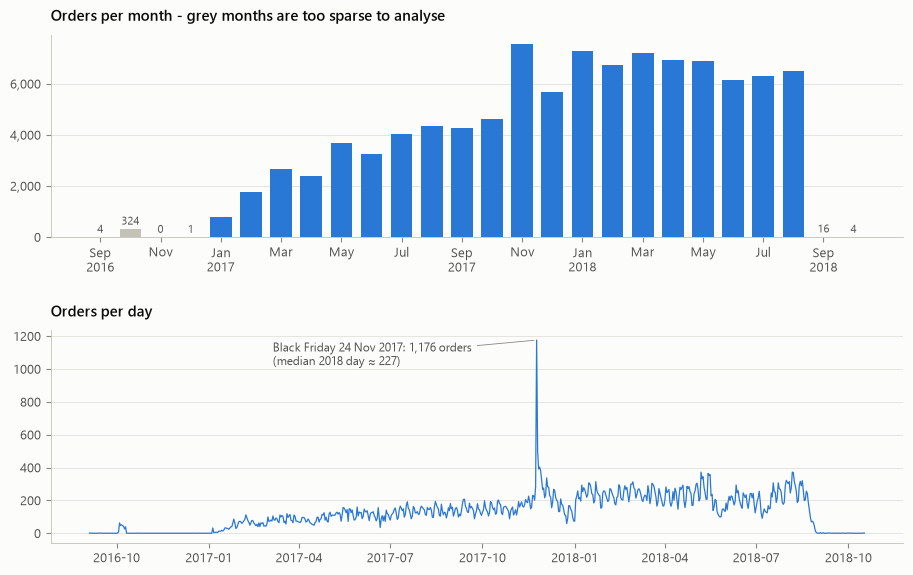

  saved 01_coverage.png


In [9]:
m = od.groupby("purchase_month").size()
full = pd.period_range("2016-09", "2018-10", freq="M")
m = m.reindex(full, fill_value=0)
daily = od.set_index("order_purchase_timestamp").resample("D").size()
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.6), gridspec_kw={"height_ratios": [1, 1.05], "hspace": 0.45})
x = np.arange(len(m))
in_win = [(p.start_time >= WINDOW[0]) and (p.start_time < WINDOW[1]) for p in m.index]
a1.bar(x, m.values, width=0.72, color=[S1 if w else AXIS for w in in_win])
a1.set_xticks(x[::2], [p.strftime("%b\n%Y") if p.month in (1, 9) or i == 0 else p.strftime("%b") for i, p in enumerate(m.index[::2])])
a1.set_title("Orders per month - grey months are too sparse to analyse")
a1.grid(axis="x", visible=False)
a1.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
for i, (p, v) in enumerate(m.items()):
    if str(p) in ("2016-09", "2016-10", "2016-11", "2016-12", "2018-09", "2018-10"):
        a1.annotate(f"{v:,}", (i, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=INK2)
a2.plot(daily.index, daily.values, color=S1, lw=0.9)
bf = daily.idxmax()
a2.annotate(f"Black Friday {bf:%d %b %Y}: {daily.max():,} orders\n(median 2018 day ≈ {daily['2018-01':'2018-08'].median():.0f})", (bf, daily.max()),
            xytext=(-190, -18), textcoords="offset points", fontsize=8.5, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
a2.set_title("Orders per day")
a2.grid(axis="x", visible=False)
save(fig, "01_coverage.png")

- **Window.** Jan 2017 – Aug 2018 holds 99,092 orders. Everything outside it is too thin to analyse.
- **Growth.** Jan–Aug 2018: 53,991 orders vs 22,968 in Jan–Aug 2017 (+135%). Inside 2018, though, volume is flat (6.2k–7.3k a month) while active sellers keep rising (Fig 3).
- **Black Friday, 24 Nov 2017:** 1,176 orders, about 5× a typical 2018 day (median 227). Orders placed that week were late 17% of the time.
- **Day of month** is flat (3,000–3,500 orders per calendar day). The 24th stands out only because of Black Friday. There is no visible payday effect.

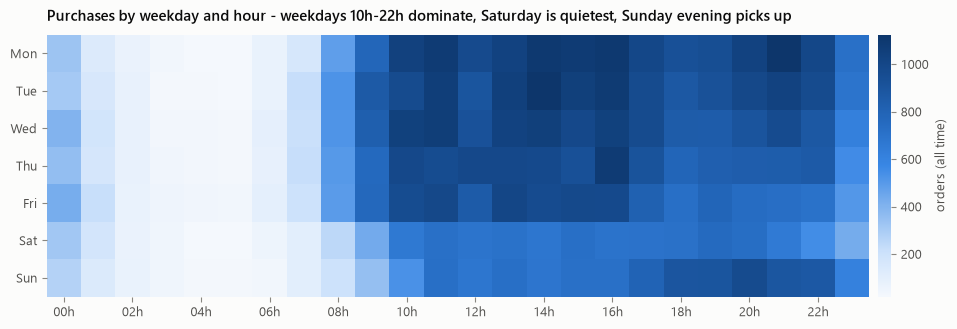

  saved 02_weekly_rhythm.png


In [10]:
wk = od.assign(dow=od.order_purchase_timestamp.dt.dayofweek, hr=od.order_purchase_timestamp.dt.hour)
heat = wk.pivot_table(index="dow", columns="hr", values="order_id", aggfunc="count")
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(heat.values, aspect="auto", cmap=BLUES)
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(0, 24, 2), [f"{h:02d}h" for h in range(0, 24, 2)])
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.outline.set_visible(False)
cb.ax.tick_params(colors=MUTED, labelcolor=INK2)
cb.set_label("orders (all time)", color=INK2)
ax.set_title("Purchases by weekday and hour - weekdays 10h-22h dominate, Saturday is quietest, Sunday evening picks up")
save(fig, "02_weekly_rhythm.png")

- Monday is the busiest day (16,196 orders) and Saturday the quietest (10,887). Buying runs 10h–22h and continues to midnight. The trough is at 5h (188 orders in two years). Sunday evening is busy.
- **Holiday fingerprint.** Delivery counts collapse on Carnival (27–28 Feb 2017, 12–13 Feb 2018), Good Friday, Corpus Christi, 7 Sep, 12 Oct, 2 Nov, Christmas and New Year. That is what real carrier scans look like. The non-holiday collapses are 16–19 Jul 2018 and 20 Jun 2017 (see §2).

### 3.2 Operations over time

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


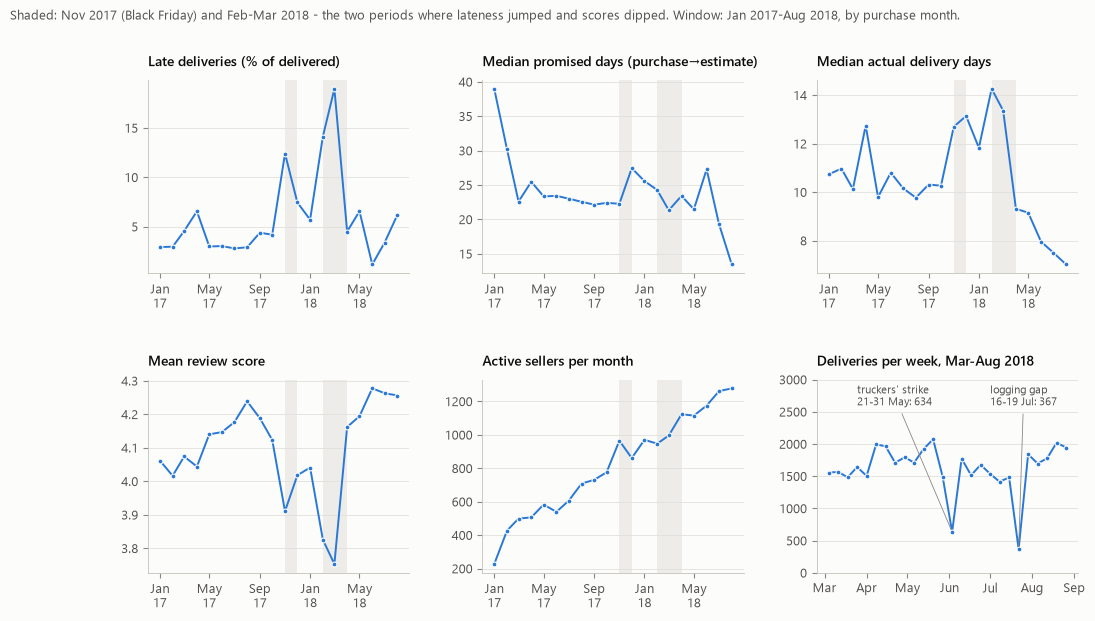

  saved 03_operations_over_time.png


In [11]:
dw = delivered[(delivered.order_purchase_timestamp >= WINDOW[0]) & (delivered.order_purchase_timestamp < WINDOW[1])]
mo = dw.groupby("purchase_month").agg(late=("is_late", "mean"), promised=("promised_d", "median"), actual=("delivery_d", "median"))
mo["score"] = reviewed[(reviewed.order_purchase_timestamp >= WINDOW[0]) & (reviewed.order_purchase_timestamp < WINDOW[1])].groupby("purchase_month").review_score.mean()
mo["sellers"] = it[(it.order_purchase_timestamp >= WINDOW[0]) & (it.order_purchase_timestamp < WINDOW[1])].groupby(it.order_purchase_timestamp.dt.to_period("M")).seller_id.nunique()
wd = delivered.set_index("order_delivered_customer_date").resample("W-SUN").size()["2018-03-01":"2018-08-31"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4), gridspec_kw={"hspace": 0.55, "wspace": 0.28})
xm = mo.index.to_timestamp()
panels = [("late", "Late deliveries (% of delivered)", lambda v: v * 100, "%"), ("promised", "Median promised days (purchase→estimate)", lambda v: v, ""),
          ("actual", "Median actual delivery days", lambda v: v, ""), ("score", "Mean review score", lambda v: v, ""),
          ("sellers", "Active sellers per month", lambda v: v, "")]
for ax, (col, title, f, unit) in zip(axes.flat, panels):
    for lo, hi in [("2017-11-01", "2017-12-01"), ("2018-02-01", "2018-04-01")]:
        ax.axvspan(pd.Timestamp(lo), pd.Timestamp(hi), color=GRID, alpha=0.55, lw=0)
    ax.plot(xm, f(mo[col]), color=S1, marker="o", ms=3.5, mec=SURF, mew=0.8)
    ax.set_title(title, fontsize=10)
    ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b\n%y"))
    ax.xaxis.set_major_locator(matplotlib.dates.MonthLocator(bymonth=[1, 5, 9]))
    ax.grid(axis="x", visible=False)
ax = axes.flat[5]
ax.plot(wd.index, wd.values, color=S1, marker="o", ms=3.5, mec=SURF, mew=0.8)
strike, gap = pd.Timestamp("2018-06-03"), pd.Timestamp("2018-07-22")  # week-ending dates
ax.annotate(f"truckers' strike\n21-31 May: {wd[strike]:,}", (strike, wd[strike]), xytext=(pd.Timestamp("2018-03-25"), 2600), textcoords="data",
            fontsize=8, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
ax.annotate(f"logging gap\n16-19 Jul: {wd[gap]:,}", (gap, wd[gap]), xytext=(pd.Timestamp("2018-07-01"), 2600), textcoords="data",
            fontsize=8, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
ax.set_ylim(0, 3000)
ax.set_title("Deliveries per week, Mar-Aug 2018", fontsize=10)
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b"))
ax.grid(axis="x", visible=False)
save(fig, "03_operations_over_time.png",
     subtitle="Shaded: Nov 2017 (Black Friday) and Feb-Mar 2018 - the two periods where lateness jumped and scores dipped. Window: Jan 2017-Aug 2018, by purchase month.")

- **Lateness is episodic.** It is 3–5% in calm months, 12.4% for Nov-2017 purchases, 14.1% for Feb 2018 and 19.0% for Mar 2018. The mean review score dips in the same months (3.91, 3.83, 3.75, against about 4.2 otherwise).
- **Feb–Mar 2018 hit every state**, hardest in Rio:

  | State | Late, Feb–Mar 2018 | Late, Apr–Jun 2018 |
  |---|---:|---:|
  | RJ | 34.3% | 4.5% |
  | BA | 25.7% | 15.1% |
  | SC | 21.8% | 2.5% |
  | RS | 16.4% | 2.6% |
  | DF | 14.8% | 3.9% |
  | MG | 14.6% | 4.0% |
  | PR | 11.2% | 2.8% |
  | SP | 8.4% | 2.3% |

  The dataset does not say why.
- **Promises kept shrinking.** The median promised time fell from 39 days (Jan 2017) to about 23 (mid-2017) and then to 13.4 (Aug 2018). Actual median delivery also fell, to 7.0 days by Aug 2018 (slightly flattered by right-censoring). The buffer between promise and delivery shrank from about 12 days to about 6.
- **Truckers' strike (21–31 May 2018):** weekly deliveries fell from about 2,000 to 634, and carrier pickups dropped with them.
- **Active sellers per month** grew 5.6×, from 227 to 1,278.

### 3.3 Customers

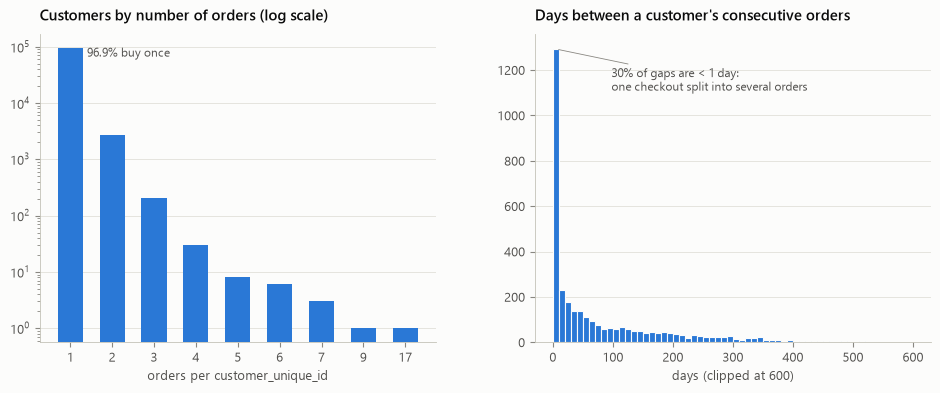

  saved 05_repeat_customers.png

== CUSTOMERS == repeaters 3.12% | genuine returners (gap>=1d) 2.21%


In [12]:
opc = od.groupby("customer_unique_id").size()
rep = od[od.customer_unique_id.isin(opc[opc > 1].index)].sort_values(["customer_unique_id", "order_purchase_timestamp"])
gaps = rep.groupby("customer_unique_id").order_purchase_timestamp.diff().dt.total_seconds().dropna() / 86400
genuine = rep.assign(gap=rep.groupby("customer_unique_id").order_purchase_timestamp.diff().dt.total_seconds() / 86400).groupby("customer_unique_id").gap.max()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4), gridspec_kw={"wspace": 0.25})
vc = opc.value_counts().sort_index()
a1.bar(vc.index.astype(str), vc.values, color=S1, width=0.6)
a1.set_yscale("log")
a1.set_title("Customers by number of orders (log scale)")
a1.set_xlabel("orders per customer_unique_id")
a1.grid(axis="x", visible=False)
a1.annotate(f"{pct((opc == 1).mean())} buy once", (0, vc.iloc[0]), xytext=(12, -6), textcoords="offset points", fontsize=8.5, color=INK2)
a2.hist(gaps.clip(upper=600), bins=np.arange(0, 610, 10), color=S1, edgecolor=SURF, lw=0.8)
a2.set_title("Days between a customer's consecutive orders")
a2.set_xlabel("days (clipped at 600)")
a2.annotate(f"{pct((gaps < 1).mean(), 0)} of gaps are < 1 day:\none checkout split into several orders", (5, ((gaps < 10).sum())),
            xytext=(40, -30), textcoords="offset points", fontsize=8.5, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
a2.grid(axis="x", visible=False)
save(fig, "05_repeat_customers.png")
print(f"\n== CUSTOMERS == repeaters {pct((opc > 1).mean(), 2)} | genuine returners (gap>=1d) {pct((genuine >= 1).sum() / len(opc), 2)}")

- 96,096 people sit behind 99,441 `customer_id`s. **96.9% ordered once.** 3.1% have more than one order, but 30% of consecutive-order gaps are under a day: a multi-seller cart split into several orders. **2,120 customers (2.2%) came back on a later day.**
- Among genuine repeat orders, 37% are in the same category as the previous order.
- Spend per person: median R$89. The top 10% of customers account for 41% of spend (Gini 0.53).
- 42% of customers live in São Paulo state, 13% in RJ and 12% in MG. São Paulo city alone accounts for 15.6%.
- 250 people ordered from more than one zip code, and 39 from more than one state.
- The return rate barely moves with the first experience. Customers whose first order (before Mar 2018) got 5★ returned 3.2% of the time, against 2.3% for a 1★ first order.

### 3.4 Sellers

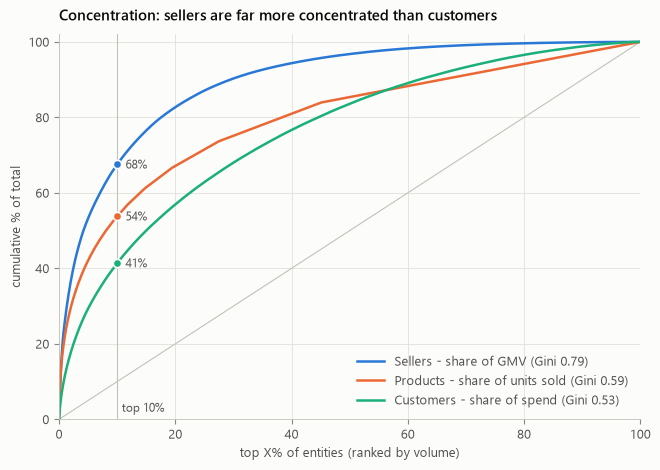

  saved 04_concentration.png


In [13]:
def top_share_curve(values):
    v = np.sort(np.asarray(values, float))[::-1]
    return np.linspace(0, 100, len(v) + 1), np.r_[0, np.cumsum(v) / v.sum() * 100]


def gini(values):
    v = np.sort(np.asarray(values, float))
    n = len(v)
    return (n + 1 - 2 * np.sum(np.cumsum(v)) / v.sum()) / n


cust_spend = od.groupby("customer_unique_id").price_sum.sum().fillna(0)
seller_gmv = it.groupby("seller_id").price.sum()
prod_units = it.groupby("product_id").size()
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot([0, 100], [0, 100], color=AXIS, lw=0.8)
ax.axvline(10, color=AXIS, lw=0.8)
ax.text(10.8, 2, "top 10%", fontsize=8.5, color=INK2)
for vals, color, name in [(seller_gmv, S1, "Sellers - share of GMV"), (prod_units, S2, "Products - share of units sold"), (cust_spend, S3, "Customers - share of spend")]:
    xs, ys = top_share_curve(vals)
    ax.plot(xs, ys, color=color, lw=1.8, label=f"{name} (Gini {gini(vals):.2f})")
    y10 = np.interp(10, xs, ys)
    ax.plot([10], [y10], "o", color=color, ms=6, mec=SURF, mew=1.2)
    ax.annotate(f"{y10:.0f}%", (10, y10), xytext=(6, -3), textcoords="offset points", fontsize=8.5, color=INK2)
ax.set_xlabel("top X% of entities (ranked by volume)")
ax.set_ylabel("cumulative % of total")
ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
ax.legend(loc="lower right")
ax.set_title("Concentration: sellers are far more concentrated than customers")
save(fig, "04_concentration.png")

- **3,095 sellers**, with a revenue Gini of 0.79. The top 1% (30 sellers) earn 25.7% of item revenue, the top 10% earn 67.5%, and the top 20% earn 82.7%.
- **Long tail:** the median seller has 6 orders; 571 sold exactly once and 1,443 sold 5 times or fewer. 55% of sellers sell in a single category.
- **High churn:** the median active lifespan is 112 days, and 41% (1,273) had no sale in Jun–Aug 2018. New sellers kept arriving at 300–565 per quarter.
- **Location:** 60% of sellers are in SP state and they carry 64% of revenue, followed by PR (9%) and MG (7%).
- **Scale vs quality:** sellers with ≤5 orders average 3.87★, against 4.08–4.13★ for larger sellers, and late rates are similar across sizes (6.4–7.2%). Among the 425 sellers with ≥50 reviewed orders, the average score ranges from 2.33 to 4.82 (5th–95th percentile: 3.60–4.52). It correlates with the seller's late rate (ρ −0.46).
- **Handling SLA:** 9.0% of delivered orders reached the carrier after the seller's `shipping_limit_date`. Those orders ended up late 20.8% of the time, against 5.4% otherwise.

### 3.5 Products and categories

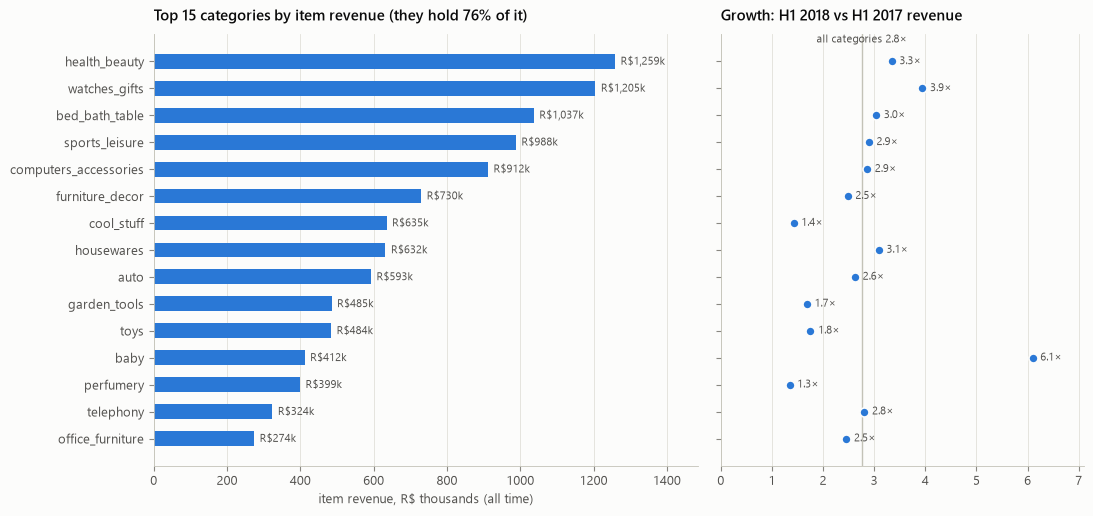

  saved 06_categories.png


In [14]:
cat = it.groupby("category").agg(gmv=("price", "sum"), items=("price", "size"), med_price=("price", "median"))
it["half"] = it.order_purchase_timestamp.dt.year.astype(str) + np.where(it.order_purchase_timestamp.dt.month <= 6, "H1", "H2")
h = it[it.half.isin(["2017H1", "2018H1"])].pivot_table(index="category", columns="half", values="price", aggfunc="sum")
cat["growth"] = h["2018H1"] / h["2017H1"]
overall_growth = h["2018H1"].sum() / h["2017H1"].sum()
top = cat.nlargest(15, "gmv").iloc[::-1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5.6), sharey=True, gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.05})
a1.barh(top.index, top.gmv / 1e3, color=S1, height=0.55)
for y, v in enumerate(top.gmv / 1e3):
    a1.text(v + 15, y, f"R${v:,.0f}k", va="center", fontsize=8, color=INK2)
a1.set_title(f"Top 15 categories by item revenue (they hold {pct(top.gmv.sum() / cat.gmv.sum(), 0)} of it)")
a1.grid(axis="y", visible=False)
a1.set_xlim(0, top.gmv.max() / 1e3 * 1.18)
a1.set_xlabel("item revenue, R$ thousands (all time)")
a2.axvline(overall_growth, color=AXIS, lw=1)
a2.text(overall_growth, len(top) - 0.3, f"all categories {overall_growth:.1f}×", fontsize=8, color=INK2, ha="center")
a2.plot(top.growth, top.index, "o", color=S1, ms=6.5, mec=SURF, mew=1.2)
for y, v in enumerate(top.growth):
    a2.text(v + 0.15, y, f"{v:.1f}×", va="center", fontsize=8, color=INK2)
a2.set_title("Growth: H1 2018 vs H1 2017 revenue")
a2.grid(axis="y", visible=False)
a2.set_xlim(0, top.growth.max() + 1)
save(fig, "06_categories.png")

- **32,951 products in 74 categories** (including "missing"). The top 5 categories take 39.7% of revenue and the top 15 take 76%.
- **55% of products sold exactly once.** 1,225 products are sold by more than one seller (up to 8). A product's price rarely changes between sales (median coefficient of variation: 0).
- **Momentum differs a lot.** Overall revenue in H1 2018 was 2.8× H1 2017. Baby grew 6.1×, stationery 4.3×, watches_gifts and musical_instruments 3.9× each. Perfumery grew only 1.3×, cool_stuff 1.4× and garden_tools 1.7×.
- **Seasonality (2017).** Because of growth, Nov+Dec held 29.4% of the year's units overall. Christmas-heavy categories sit well above that: electronics 43.7%, stationery 42.4%, watches_gifts 36.6%, toys 36.1%. Office_furniture (18.8%) and luggage (19.9%) sit below. Black Friday itself was led by bed_bath_table (14% of that day's items) and furniture_decor (10%).
- **Listing quality does not track sales.** The Spearman correlation of units sold with photo count, description length and name length is 0.015–0.027. Description length tracks price a little (0.21), and weight tracks price clearly (0.53).
- Product names cluster at exactly 60 characters (2,182 products; 710 go above), which looks like a listing-title guideline.

### 3.6 Money: prices, freight, payments

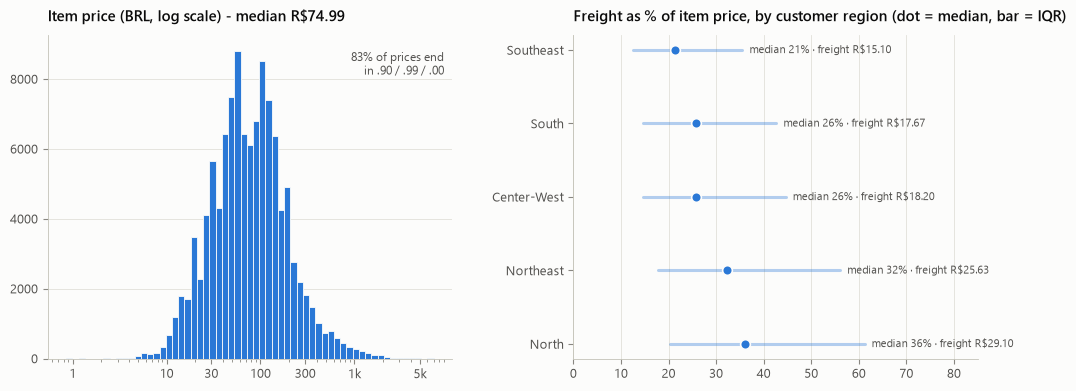

  saved 07_price_freight.png


In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"wspace": 0.3})
bins = np.logspace(np.log10(0.85), np.log10(7000), 60)
a1.hist(it.price, bins=bins, color=S1, edgecolor=SURF, lw=0.6)
a1.set_xscale("log")
a1.set_xticks([1, 10, 30, 100, 300, 1000, 5000], ["1", "10", "30", "100", "300", "1k", "5k"])
a1.set_title(f"Item price (BRL, log scale) - median R${it.price.median():.2f}")
a1.grid(axis="x", visible=False)
cents = (it.price * 100).round().astype(int) % 100
a1.text(0.98, 0.95, f"{pct(cents.isin([90, 99, 0]).mean(), 0)} of prices end\nin .90 / .99 / .00", transform=a1.transAxes, fontsize=8.5, color=INK2, va="top", ha="right")
order_r = ["Southeast", "South", "Center-West", "Northeast", "North"]
q = it.groupby("c_region").fr_ratio.quantile([0.25, 0.5, 0.75]).unstack().loc[order_r]
fm = it.groupby("c_region").freight_value.median().loc[order_r]
for y, (r, row) in enumerate(q.iterrows()):
    a2.plot([row[0.25] * 100, row[0.75] * 100], [y, y], color=S1, lw=2.2, alpha=0.35, solid_capstyle="round")
    a2.plot(row[0.5] * 100, y, "o", color=S1, ms=7, mec=SURF, mew=1.2)
    a2.text(row[0.75] * 100 + 1.5, y, f"median {row[0.5] * 100:.0f}% · freight R${fm[r]:.2f}", va="center", fontsize=8, color=INK2)
a2.set_yticks(range(len(order_r)), order_r)
a2.invert_yaxis()
a2.set_xlim(0, 85)
a2.set_title("Freight as % of item price, by customer region (dot = median, bar = IQR)")
a2.grid(axis="y", visible=False)
save(fig, "07_price_freight.png")

- **Item prices are log-normal:** median R$74.99, 99th percentile R$890, maximum R$6,735. Order value (items only) has a median of R$86.90; with freight, the median payment is R$105.29.
- **Charm pricing:** 35.6% of prices end in .90, 29.1% in .00 and 18.2% in .99.
- **Freight:** the median is R$16.26 per item and 383 items shipped free. Freight exceeds the item price for 3.7% of items, and the median freight is 23% of item price. It is charged per unit, so every unit of the same product carries the same freight.
- **What drives freight (Spearman):** distance 0.63, then weight 0.45 and price 0.44, then volume 0.37.
- **Regional gap:** the median freight is R$29.10 (36% of price) in the North against R$15.10 (21%) in the Southeast. By contrast, the payment mix barely changes by region (boleto 18–23% everywhere).

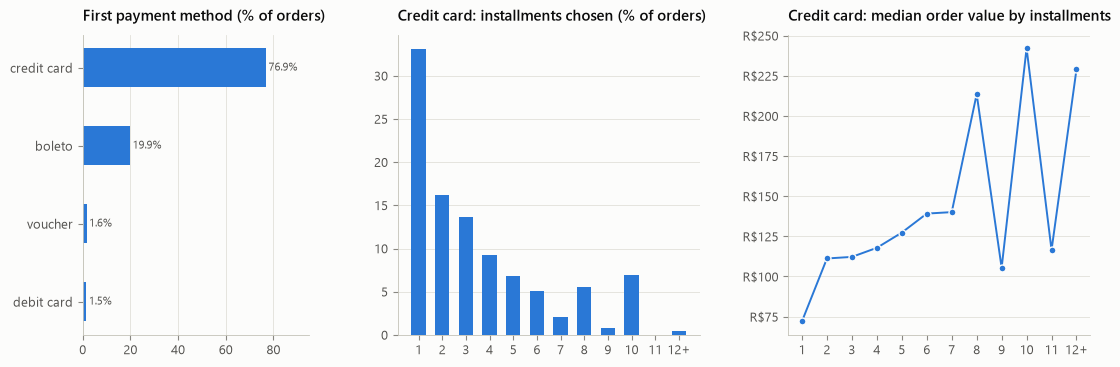

  saved 08_payments.png


In [16]:
cc = od[od.main_pay == "credit_card"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={"wspace": 0.32, "width_ratios": [0.9, 1.2, 1.2]})
share = od.main_pay.value_counts(normalize=True).drop("not_defined", errors="ignore").iloc[::-1]
axes[0].barh(share.index.str.replace("_", " "), share.values * 100, color=S1, height=0.5)
for y, v in enumerate(share.values * 100):
    axes[0].text(v + 1, y, f"{v:.1f}%", va="center", fontsize=8, color=INK2)
axes[0].set_xlim(0, 95)
axes[0].set_title("First payment method (% of orders)")
axes[0].grid(axis="y", visible=False)
inst = cc.max_inst.clip(1, 12).value_counts(normalize=True).sort_index()
axes[1].bar(inst.index.astype(int).astype(str).str.replace("12", "12+"), inst.values * 100, color=S1, width=0.6)
axes[1].set_title("Credit card: installments chosen (% of orders)")
axes[1].grid(axis="x", visible=False)
med = cc.groupby(cc.max_inst.clip(1, 12)).pay_total.median()
axes[2].plot(med.index.astype(int).astype(str).str.replace("12", "12+"), med.values, color=S1, marker="o", ms=5, mec=SURF, mew=1)
axes[2].set_title("Credit card: median order value by installments")
axes[2].yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"R${v:,.0f}"))
axes[2].grid(axis="x", visible=False)
save(fig, "08_payments.png")

- The first payment method is a credit card in 76.9% of orders, boleto in 19.9%, a voucher in 1.6% and a debit card in 1.5%. Vouchers appear somewhere in 3.9% of orders, usually alongside a card.
- **Two-thirds of card orders (66.9%) are split into installments.** The common counts are 1, 2, 3 and then 10 (6.9%, likely an interest-free promotion). The median order value rises from R$72 at 1× to R$242 at 10×. Orders at 8× and 10× are about twice as large as those at 9× and 11×.
- **Boleto is slow to clear:** median approval takes 29 hours against 0.3 hours for cards.
- Orders whose first payment is a voucher end `canceled`/`unavailable` 5.3% of the time, against 1.2% for other orders.
- The debit-card share rose to about 4% in Q3 2018, up from about 1%.

### 3.7 Logistics

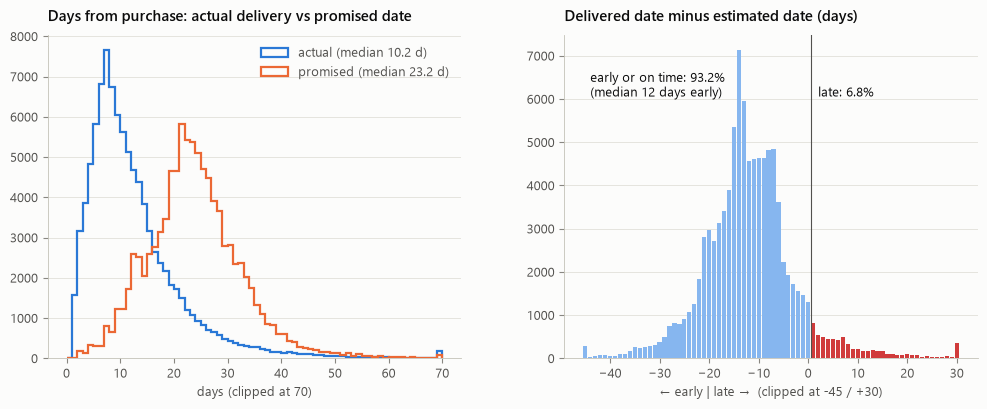

  saved 09_promise_vs_reality.png


In [17]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"wspace": 0.25})
b = np.arange(0, 71, 1)
a1.hist(delivered.delivery_d.clip(upper=70), bins=b, histtype="step", color=S1, lw=1.6, label=f"actual (median {delivered.delivery_d.median():.1f} d)")
a1.hist(delivered.promised_d.clip(upper=70), bins=b, histtype="step", color=S2, lw=1.6, label=f"promised (median {delivered.promised_d.median():.1f} d)")
a1.legend(loc="upper right")
a1.set_title("Days from purchase: actual delivery vs promised date")
a1.set_xlabel("days (clipped at 70)")
a1.grid(axis="x", visible=False)
ld = delivered.late_d.clip(-45, 30).value_counts().sort_index()
a2.bar(ld.index, ld.values, width=0.85, color=[CRITICAL if v > 0 else "#86b6ef" for v in ld.index])
a2.axvline(0.5, color=INK2, lw=0.8)
a2.text(2, ld.max() * 0.85, f"late: {pct(delivered.is_late.mean())}", color=INK, fontsize=9)
a2.text(-44, ld.max() * 0.85, f"early or on time: {pct(1 - delivered.is_late.mean())}\n(median {-delivered.late_d.median():.0f} days early)", color=INK, fontsize=9)
a2.set_title("Delivered date minus estimated date (days)")
a2.set_xlabel("← early | late →  (clipped at -45 / +30)")
a2.grid(axis="x", visible=False)
save(fig, "09_promise_vs_reality.png")

- **Where the time goes:** the median delivery takes 10.2 days. Carrier transit is 7.1 days (about 76% of the total), seller handling 1.8 days, and payment approval 0.3 hours.
- **Padding:** the median promise is 23.2 days, so orders arrive at 0.45× the promised time. 93.2% arrive on time or early (median 12 days early) and 6.8% are late.
- Deliveries happen Monday to Friday (5,463 on Saturdays and 1,206 on Sundays across two years). Carriers almost never pick up on a Sunday (36 times).

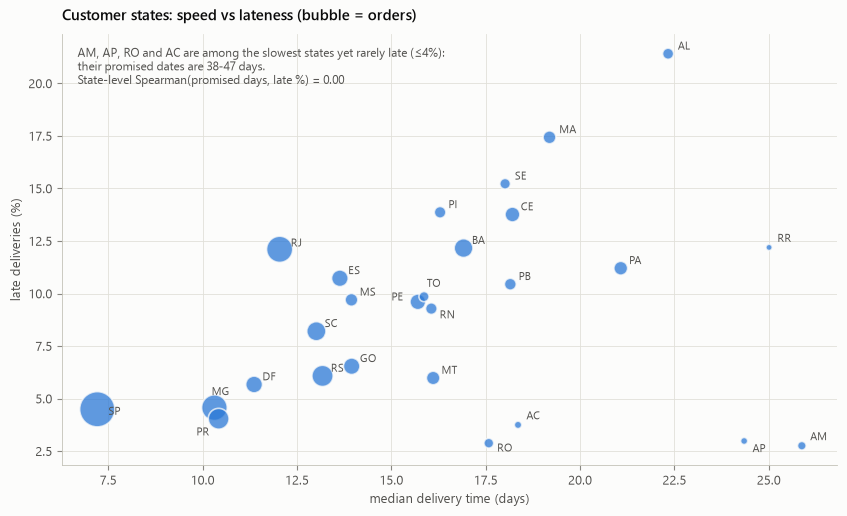

  saved 10_states_speed_vs_late.png


In [18]:
st = delivered.groupby("customer_state").agg(n=("order_id", "size"), med=("delivery_d", "median"), late=("is_late", "mean"), promised=("promised_d", "median"))
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.scatter(st.med, st.late * 100, s=np.sqrt(st.n) * 3.2, color=S1, alpha=0.75, edgecolor=SURF, linewidth=1.2)
offsets = {"SP": (8, -4), "RJ": (8, 2), "MG": (-2, 9), "PR": (-16, -12), "AM": (6, 4), "AP": (6, -8), "RR": (6, 4), "AL": (7, 3), "MA": (7, 3), "SE": (7, 3),
           "RO": (6, -6), "AC": (6, 4), "TO": (2, 7), "PE": (-19, 1), "RN": (6, -7)}
for s_, row in st.iterrows():
    ax.annotate(s_, (row.med, row.late * 100), xytext=offsets.get(s_, (6, 3)), textcoords="offset points", fontsize=8, color=INK2)
ax.set_xlabel("median delivery time (days)")
ax.set_ylabel("late deliveries (%)")
rho = stats.spearmanr(st.promised, st.late).statistic
ax.set_title("Customer states: speed vs lateness (bubble = orders)")
ax.text(0.02, 0.97, f"AM, AP, RO and AC are among the slowest states yet rarely late (≤4%):\ntheir promised dates are 38-47 days.\nState-level Spearman(promised days, late %) = {rho:.2f}",
        transform=ax.transAxes, ha="left", va="top", fontsize=8.5, color=INK2)
save(fig, "10_states_speed_vs_late.png")

- **Distance explains speed.** At state level the Spearman correlation between distance and median delivery time is 0.90; at order level it is 0.54. Weight barely matters (0.09).
- **Slow is not the same as late.** SP takes 7.2 days and is 4.5% late; AM takes 25.9 days but, with a 45-day promise, is 2.8% late. RJ takes 12.0 days yet is 12.1% late, AL is 21.4% late and MA 17.4%. Across states, promised days and late % correlate at **0.00**. Lateness reflects how each estimate was set, not distance.

### 3.8 Geography

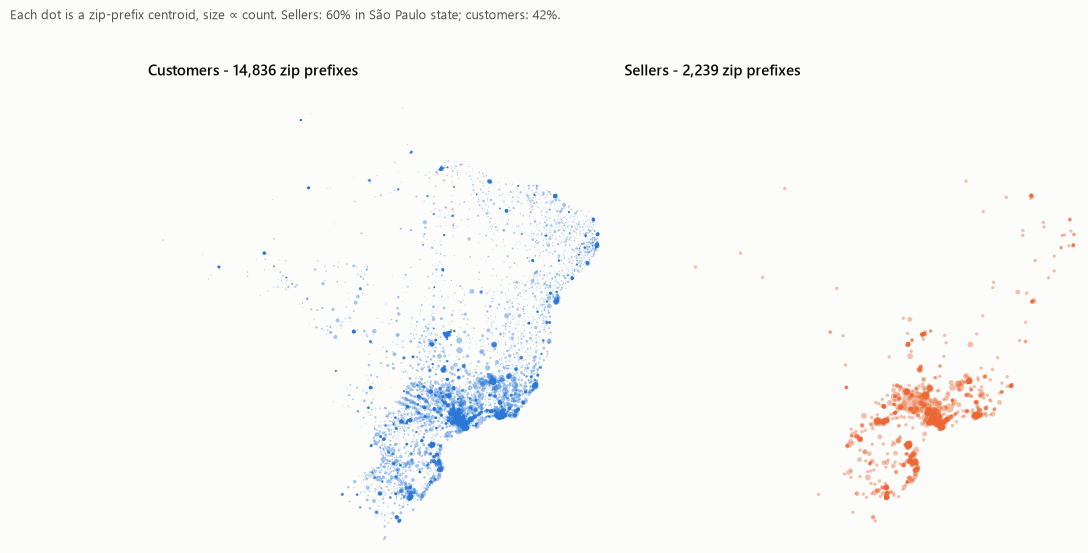

  saved 11_geography.png


In [19]:
cz = od.groupby("customer_zip_code_prefix").size().rename("n").to_frame().join(zc, how="inner")
sz = sellers.groupby("seller_zip_code_prefix").size().rename("n").to_frame().join(zc, how="inner")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 6.2), gridspec_kw={"wspace": 0.05})
for ax, df, color, title, k in [(a1, cz, S1, f"Customers - {len(cz):,} zip prefixes", 0.35), (a2, sz, S2, f"Sellers - {len(sz):,} zip prefixes", 6)]:
    ax.scatter(df.lng, df.lat, s=np.clip(df.n, 1, 60) * k, color=color, alpha=0.4, lw=0)
    ax.set_xlim(-74, -34.5)
    ax.set_ylim(-34, 5.5)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
save(fig, "11_geography.png", subtitle=f"Each dot is a zip-prefix centroid, size ∝ count. Sellers: {pct((sellers.seller_state == 'SP').mean(), 0)} in São Paulo state; customers: {pct((customers.customer_state == 'SP').mean(), 0)}.")

- Customers follow Brazil's population: a dense coast, the SP–RJ–BH triangle, and a sparse Amazon. Sellers form a tight cluster centred on São Paulo, with smaller groups in PR, MG and SC.
- 36% of items stay within one state. São Paulo sellers ship 71% of all items. The median seller-to-customer distance is 432 km, and only 12% of items travel under 50 km. Distances come from zip-prefix centroids, so they are approximate.

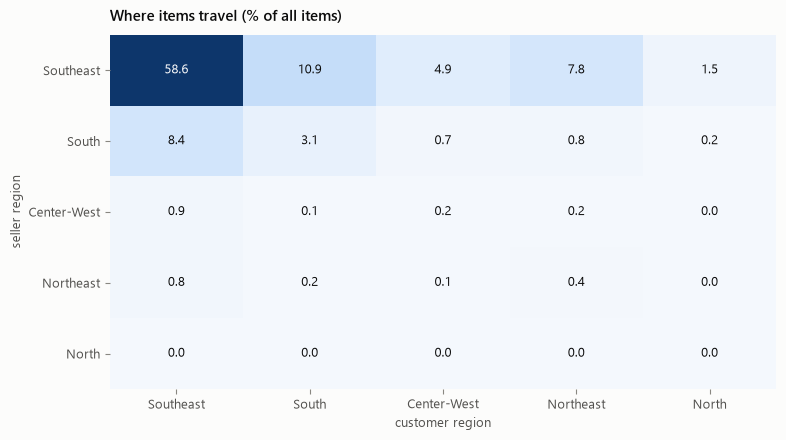

  saved 12_region_flows.png


In [20]:
flow = pd.crosstab(it.s_region, it.c_region, normalize="all").reindex(index=order_r, columns=order_r).fillna(0) * 100
fig, ax = plt.subplots(figsize=(8.6, 4.6))
im = ax.imshow(flow.values, cmap=BLUES, vmin=0, vmax=flow.values.max(), aspect="auto")
for (i_, j_), v in np.ndenumerate(flow.values):
    ax.text(j_, i_, f"{v:.1f}", ha="center", va="center", fontsize=9, color="white" if v > flow.values.max() * 0.55 else INK)
ax.set_xticks(range(5), order_r, rotation=0)
ax.set_yticks(range(5), order_r)
ax.set_xlabel("customer region")
ax.set_ylabel("seller region")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Where items travel (% of all items)")
save(fig, "12_region_flows.png")

- **Southeast → Southeast is 58.6% of all items.** The Southeast supplies every region, and sellers in the North account for under 0.1% of items.

### 3.9 Reviews and text

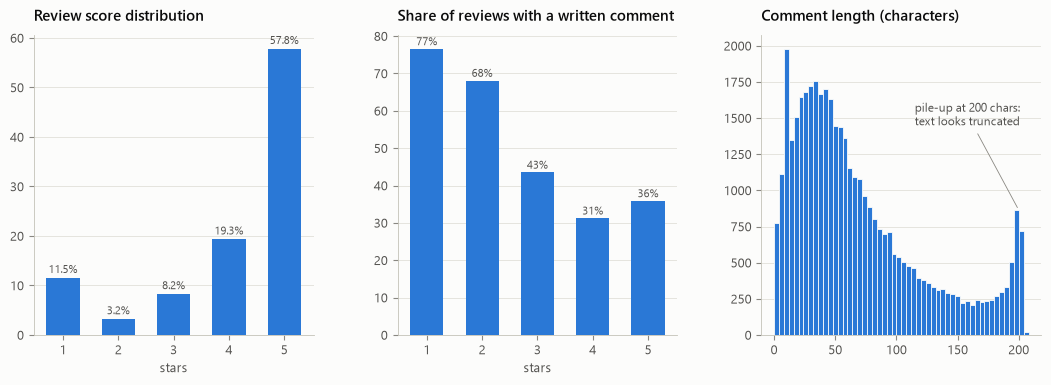

  saved 13_reviews_overview.png


In [21]:
rv = reviews.assign(has_msg=reviews.review_comment_message.notna())
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={"wspace": 0.3})
sd = rv.review_score.value_counts(normalize=True).sort_index() * 100
axes[0].bar(sd.index.astype(str), sd.values, color=S1, width=0.6)
for x_, v in zip(range(5), sd.values):
    axes[0].text(x_, v + 1, f"{v:.1f}%", ha="center", fontsize=8, color=INK2)
axes[0].set_title("Review score distribution")
axes[0].set_xlabel("stars")
axes[0].grid(axis="x", visible=False)
cr = rv.groupby("review_score").has_msg.mean() * 100
axes[1].bar(cr.index.astype(str), cr.values, color=S1, width=0.6)
for x_, v in zip(range(5), cr.values):
    axes[1].text(x_, v + 1, f"{v:.0f}%", ha="center", fontsize=8, color=INK2)
axes[1].set_title("Share of reviews with a written comment")
axes[1].set_xlabel("stars")
axes[1].grid(axis="x", visible=False)
axes[2].hist(msg_len, bins=np.arange(0, 212, 4), color=S1, edgecolor=SURF, lw=0.6)
axes[2].annotate("pile-up at 200 chars:\ntext looks truncated", (200, (msg_len.between(196, 199)).sum()), xytext=(115, 1450), textcoords="data",
                 fontsize=8.5, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
axes[2].set_title("Comment length (characters)")
axes[2].grid(axis="x", visible=False)
save(fig, "13_reviews_overview.png")

- **J-shaped scores:** 57.8% 5★, 19.3% 4★, 8.2% 3★, 3.2% 2★, 11.5% 1★ (mean 4.09).
- 41% of reviews carry a comment. Unhappy customers write more often (77% at 1★ vs 31% at 4★) and write longer (median 89 characters at 1★ vs 42 at 5★). 777 comments are three characters or fewer ("Bom", "Ok", ".").
- **Survey timing:** the survey goes out on delivery or on the estimated date, whichever comes first. The median review is created the day after delivery. 4.9% of reviews on delivered orders were answered before the recorded delivery, and those average 1.74★ against 4.28★. Reviews also exist for `canceled` (1.80★), `unavailable` (1.53★) and still-`shipped` (2.00★) orders.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


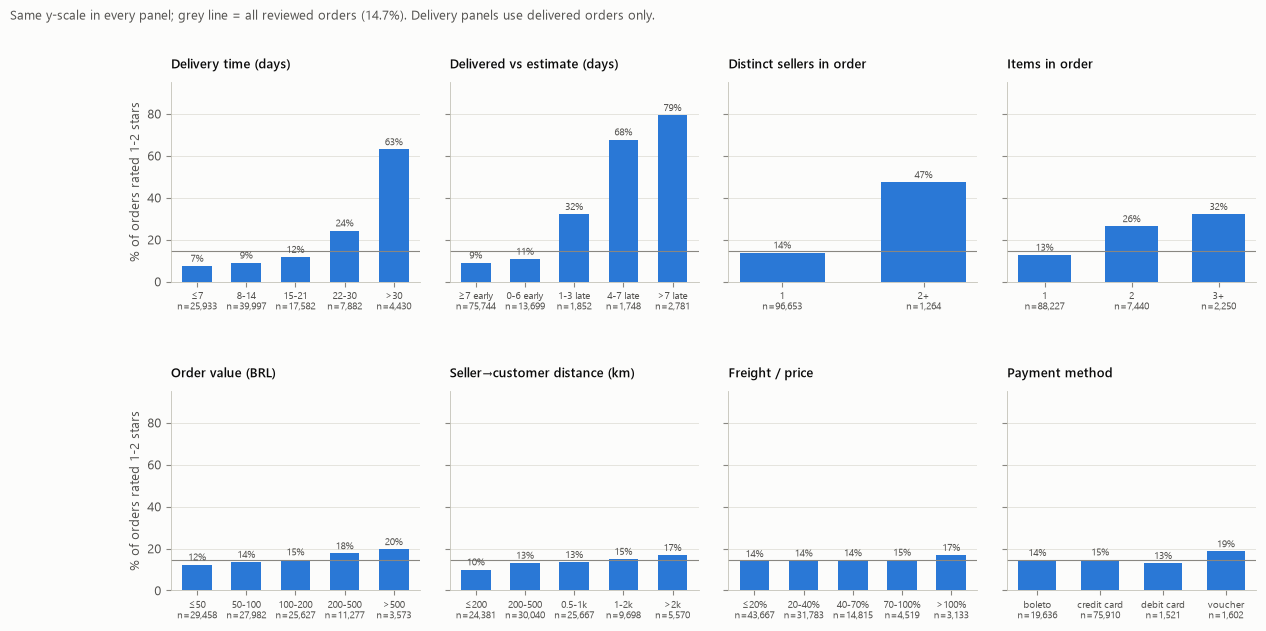

  saved 14_score_factors.png


In [22]:
dd = reviewed[reviewed.order_status == "delivered"]
base_rate = (reviewed.review_score <= 2).mean() * 100
factor_panels = [
    ("Delivery time (days)", dd, "delivery_d", [0, 7, 14, 21, 30, 400], ["≤7", "8-14", "15-21", "22-30", ">30"]),
    ("Delivered vs estimate (days)", dd, "late_d", [-400, -7, 0, 3, 7, 400], ["≥7 early", "0-6 early", "1-3 late", "4-7 late", ">7 late"]),
    ("Distinct sellers in order", reviewed, "n_sellers", [0, 1, 10], ["1", "2+"]),
    ("Items in order", reviewed, "n_items", [0, 1, 2, 100], ["1", "2", "3+"]),
    ("Order value (BRL)", reviewed, "price_sum", [0, 50, 100, 200, 500, 20000], ["≤50", "50-100", "100-200", "200-500", ">500"]),
    ("Seller→customer distance (km)", dd, "max_dist_km", [-1, 200, 500, 1000, 2000, 4000], ["≤200", "200-500", "0.5-1k", "1-2k", ">2k"]),
    ("Freight / price", reviewed, "fr_ratio", [-0.01, 0.2, 0.4, 0.7, 1, 100], ["≤20%", "20-40%", "40-70%", "70-100%", ">100%"]),
    ("Payment method", reviewed[reviewed.main_pay != "not_defined"], "main_pay", None, None),
]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.6), sharey=True, gridspec_kw={"hspace": 0.55, "wspace": 0.12})
for ax, (title, df, col, bins_, labels) in zip(axes.flat, factor_panels):
    key = pd.cut(df[col], bins_, labels=labels) if bins_ else df[col].str.replace("_", " ")
    g = df.groupby(key, observed=True).review_score.agg(low=lambda s: (s <= 2).mean() * 100, n="size")
    ax.bar(range(len(g)), g["low"], color=S1, width=0.6)
    ax.axhline(base_rate, color=MUTED, lw=0.8)
    for x_, (v, n) in enumerate(zip(g["low"], g["n"])):
        ax.text(x_, v + 2, f"{v:.0f}%", ha="center", fontsize=7.5, color=INK2)
    ax.set_xticks(range(len(g)), [f"{l}\nn={n:,}" for l, n in zip(g.index, g["n"])], fontsize=7)
    ax.set_title(title, fontsize=9.5)
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, 95)
axes[0, 0].set_ylabel("% of orders rated 1-2 stars")
axes[1, 0].set_ylabel("% of orders rated 1-2 stars")
save(fig, "14_score_factors.png",
     subtitle=f"Same y-scale in every panel; grey line = all reviewed orders ({base_rate:.1f}%). Delivery panels use delivered orders only.")

This is one lens among many: the share of orders rated 1–2★ (baseline 14.7%) across eight factors, all on the same scale.

- **Big movers:**
  - Delivered vs estimate: 9% when ≥7 days early, 79% when >7 days late.
  - Delivery time: 7% at ≤7 days, 63% beyond 30 days.
  - Two or more sellers: 47% vs 14%.
  - Items in the order: 13% with one item, 32% with three or more.
- **Small movers:** order value (12% → 20%) and distance (10% → 17%).
- **Flat:** freight as a share of price (14–17%) and payment method (13–15%, vouchers 19%).
- Category matters even among on-time orders: office_furniture averages 3.77★ and books_general_interest 4.64★.

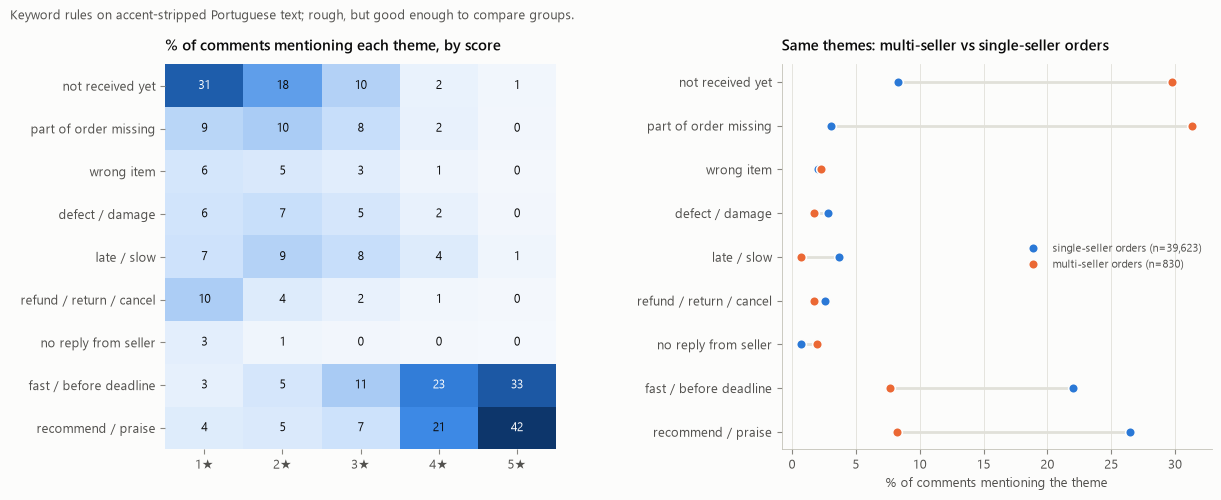

  saved 15_text_themes.png


In [23]:
def norm_text(s):
    s = unicodedata.normalize("NFKD", s.lower())
    return " ".join(re.findall(r"[a-z]+", "".join(ch for ch in s if not unicodedata.combining(ch))))


THEMES = {
    "not received yet": r"nao recebi|ainda nao (chegou|recebi)|nao chegou|nao foi entregue|aguardando",
    "part of order missing": r"(so|apenas|somente) (recebi|veio|chegou) (um|uma|1)|faltou|faltando|falta (um|uma|o|a)|incomplet|veio (so|apenas)|um dos|recebi (so|apenas)",
    "wrong item": r"errad|diferente do|outro produto|veio outro|nao era o",
    "defect / damage": r"defeito|quebrad|danific|nao funciona|parou de funcionar|rasgad|amassad|falsificad|trincad",
    "late / slow": r"atras|demor|fora do prazo|passou do prazo|depois do prazo",
    "refund / return / cancel": r"reembols|estorno|devolu|cancel|dinheiro de volta",
    "no reply from seller": r"sem resposta|nenhum retorno|sem retorno|nao (tive|obtive) (nenhum |nenhuma )?(retorno|resposta)|nao respond|nenhuma resposta",
    "fast / before deadline": r"antes do prazo|chegou rapido|entrega rapida|muito rapid|super rapid|dentro do prazo|no prazo",
    "recommend / praise": r"recomendo|otimo|excelente|perfeito|adorei|amei|parabens",
}
com = reviews.dropna(subset=["review_comment_message"]).copy()
com["t"] = com.review_comment_message.map(norm_text)
theme_rate = pd.DataFrame({k: com.groupby("review_score").t.apply(lambda s, p=v: s.str.contains(p).mean() * 100) for k, v in THEMES.items()}).T
multi_ids = od.loc[od.n_sellers > 1, "order_id"]
single_ids = od.loc[od.n_sellers == 1, "order_id"]
ms_rate = pd.DataFrame({
    "single-seller orders": {k: com[com.order_id.isin(single_ids)].t.str.contains(v).mean() * 100 for k, v in THEMES.items()},
    "multi-seller orders": {k: com[com.order_id.isin(multi_ids)].t.str.contains(v).mean() * 100 for k, v in THEMES.items()}})
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 5), gridspec_kw={"width_ratios": [1, 1.1], "wspace": 0.55})
im = a1.imshow(theme_rate.values, cmap=BLUES, aspect="auto")
for (i_, j_), v in np.ndenumerate(theme_rate.values):
    a1.text(j_, i_, f"{v:.0f}", ha="center", va="center", fontsize=8.5, color="white" if v > theme_rate.values.max() * 0.55 else INK)
a1.set_xticks(range(5), [f"{s}★" for s in theme_rate.columns])
a1.set_yticks(range(len(theme_rate)), theme_rate.index)
a1.grid(False)
for s in a1.spines.values():
    s.set_visible(False)
a1.set_title("% of comments mentioning each theme, by score")
yy = np.arange(len(ms_rate))
a2.hlines(yy, ms_rate.min(axis=1), ms_rate.max(axis=1), color=GRID, lw=2)
a2.plot(ms_rate["single-seller orders"], yy, "o", color=S1, ms=7, mec=SURF, mew=1.2, label=f"single-seller orders (n={com.order_id.isin(single_ids).sum():,})")
a2.plot(ms_rate["multi-seller orders"], yy, "o", color=S2, ms=7, mec=SURF, mew=1.2, label=f"multi-seller orders (n={com.order_id.isin(multi_ids).sum():,})")
a2.set_yticks(yy, ms_rate.index)
a2.invert_yaxis()
a2.set_xlabel("% of comments mentioning the theme")
a2.legend(loc="center right", fontsize=8)
a2.grid(axis="y", visible=False)
a2.set_title("Same themes: multi-seller vs single-seller orders")
save(fig, "15_text_themes.png", subtitle="Keyword rules on accent-stripped Portuguese text; rough, but good enough to compare groups.")

- Low-score comments are dominated by "not received yet" (31% of 1★ comments), followed by missing parts, refund/cancellation and defects. High-score comments talk about speed ("antes do prazo", before the deadline) and recommendation.
- **Multi-seller orders talk differently.** "Part of the order is missing" appears in 31% of their comments (3% for single-seller orders) and "not received" in 30% (8%). Yet their single timestamp says they arrived faster (median 7.9 vs 10.3 days) and less often late. The order-level delivery date apparently records one shipment, not all of them.

### 3.10 How the numeric variables move together

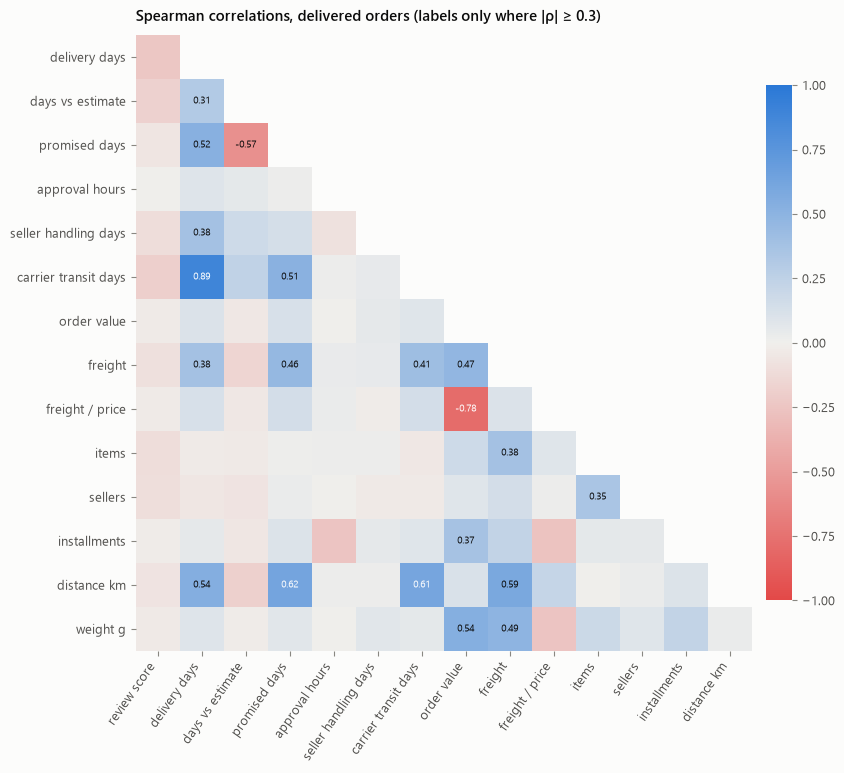

  saved 16_correlations.png


In [24]:
cols = {"review_score": "review score", "delivery_d": "delivery days", "late_d": "days vs estimate", "promised_d": "promised days",
        "approve_h": "approval hours", "to_carrier_d": "seller handling days", "carrier_to_cust_d": "carrier transit days",
        "price_sum": "order value", "freight_sum": "freight", "fr_ratio": "freight / price", "n_items": "items", "n_sellers": "sellers",
        "max_inst": "installments", "max_dist_km": "distance km", "weight_sum": "weight g"}
cm = delivered[list(cols)].corr(method="spearman").rename(index=cols, columns=cols).iloc[1:, :-1]  # drop the diagonal
mask = np.triu(np.ones_like(cm, dtype=bool), 1)
fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(np.where(mask, np.nan, cm.values), cmap=DIVERGING, vmin=-1, vmax=1)
for (i_, j_), v in np.ndenumerate(cm.values):
    if not mask[i_, j_] and abs(v) >= 0.3:
        ax.text(j_, i_, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.6 else INK)
ax.set_xticks(range(cm.shape[1]), cm.columns, rotation=55, ha="right")
ax.set_yticks(range(cm.shape[0]), cm.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cb.outline.set_visible(False)
cb.ax.tick_params(colors=MUTED, labelcolor=INK2)
ax.set_title("Spearman correlations, delivered orders (labels only where |ρ| ≥ 0.3)")
save(fig, "16_correlations.png")

- **Structural pairs:**
  - delivery days ↔ carrier transit: 0.89
  - order value ↔ freight share: −0.78
  - distance ↔ promised days: 0.62
  - distance ↔ carrier transit: 0.61
  - distance ↔ freight: 0.59
  - promised days ↔ days vs estimate: −0.57
  - order value ↔ weight: 0.54
- **Review score has no strong monotonic partner.** Every |ρ| is below 0.25: delivery days −0.23, transit −0.19, days vs estimate −0.18, items −0.11. Its relationships are threshold-shaped (Fig 14) rather than linear, so linear correlation understates them.

## 4. Surprises and open questions

1. **What does `order_delivered_customer_date` record for a multi-seller order?** The text says customers often got only part of it.
2. **Why did Feb–Mar 2018 go wrong everywhere, and worst in RJ?** It was a system-wide event, not a single route.
3. **What happened to the delivery log on 16–19 Jul 2018 and 20 Jun 2017?** Pickups continued while deliveries stopped being recorded.
4. **Why is 2018 flat while sellers keep joining,** and 41% of sellers go quiet?
5. **Why are 8× and 10× installment orders twice as large as 9× and 11×?** Promotional installment caps are a likely explanation.
6. **Are voucher orders a different population?** With a 5.3% cancel/unavailable rate, they could be compensation or replacement orders.
7. **Why does carrier pickup come before payment approval in 1,359 orders?** Is approval logged after the fact for some payment flows?
8. **What changed in Jul–Aug 2018?** The median promise dropped to 13.4 days, which looks like a policy change.

## 5. Traps for anyone modelling this

- **Grain and fan-out.** Items, payments and reviews all have several rows per order. Aggregate to order level before joining, or revenue and counts inflate.
- **Person vs order.** `customer_id` is per order. Customer-level work needs `customer_unique_id`, and repeat behaviour is rare (2.2%).
- **Edges of time.** 2016 is sparse. At the end, orders placed in Aug 2018 still include 47 in `shipped` status and 84 canceled, and slow deliveries are under-represented (right-censoring).
- **Regime changes.** Promises shrank, and there were disruptions in Nov 2017, Feb–Mar 2018 and May 2018. Random train/test splits mix regimes, so split by time.
- **Leakage.** Delivered dates, delivery duration, the late flag, review timestamps and the final `order_status` are all known only after purchase. The *estimated* delivery date is known at purchase.
- **Review semantics.** Scores are J-shaped and imbalanced, one survey can cover several orders, some orders have 2–3 reviews, and undelivered orders get reviewed too.
- **Text.** Comments are truncated at 200 characters, company names are Game of Thrones placeholders, and Portuguese appears both with and without accents.
- **Geolocation.** Deduplicate, filter to Brazil, use a per-prefix centroid, and accept that 279 customers have no coordinates.
- **Calendar.** Holidays and the logging gaps distort day-level delivery metrics.

## 6. Directions this data can support (a neutral menu)

| Direction | Why the data supports it | Watch out for |
|---|---|---|
| Demand / sales forecasting | 20 months of daily orders, Black Friday, holiday effects | Only one Black Friday; the 2018 plateau |
| Delivery-time (ETA) estimation | 96k delivered orders with stage timestamps and distance | Multi-seller ambiguity, holidays, disruptions |
| Estimate calibration (how much padding) | Promised vs actual per state and month | Estimates shrink over time |
| Freight pricing | Distance, weight, dimensions, region | Freight is charged per unit |
| Seller performance and churn | 3,095 sellers, handling SLA, scores, lifespans | Most sellers have very few orders |
| Category and assortment strategy | 74 categories, growth, seasonality | 610 products without a category |
| Payment behaviour | Installments, boleto, vouchers | Voucher meaning is unclear |
| Geospatial logistics | Zip centroids, region flows | Geolocation noise |
| Customer segmentation / CLV | 96k people | 97% bought once |
| Review text / NLP | 41k Portuguese comments | Truncation, placeholders |
| Review-score / satisfaction modelling | 98.7k scored orders, many candidate drivers | Leakage, J-shape, survey timing |
| Operational anomaly detection | Logging gap, disruptions, timestamp contradictions | Few labelled events |

## 7. Recommended preprocessing

1. Read zip prefixes as strings. Rename the two `*_lenght` columns. Read the translation file as `utf-8-sig`.
2. Keep Jan 2017 – Aug 2018 for trend work, and flag the last weeks as right-censored.
3. Build an order-level table (items, payments and reviews aggregated) before joining anything else.
4. Geolocation: drop exact duplicates, apply a Brazil bounding box (lat −33.8…5.3, lng −74…−34.7), and take the median point per prefix.
5. Flag timestamp contradictions (§2) rather than silently dropping them, since they may be informative.
6. Normalise city names (strip accents, lowercase), or work at zip/state level.
7. Add a holiday calendar and flags for 16–19 Jul 2018 and 20 Jun 2017 to any day-level delivery analysis.

## Key numbers quoted in this report

The figures above print only what they plot; this cell prints the remaining numbers the text relies on.

In [25]:
print("\n== KEY NUMBERS ==")
print(f"sellers top 10% GMV share {np.interp(10, *top_share_curve(seller_gmv)):.1f}% | gini sellers {gini(seller_gmv):.2f}, customers {gini(cust_spend):.2f}, products {gini(prod_units):.2f}")
print(f"products sold once {pct((prod_units == 1).mean())} | late {pct(delivered.is_late.mean(), 2)} | median actual/promised {(delivered.delivery_d / delivered.promised_d).median():.2f}")
print(f"multi-seller orders: n={int((od.n_sellers > 1).sum())}, mean score {reviewed[reviewed.n_sellers > 1].review_score.mean():.2f} vs {reviewed[reviewed.n_sellers == 1].review_score.mean():.2f}; "
      f"late {pct(delivered[delivered.n_sellers > 1].is_late.mean())} vs {pct(delivered[delivered.n_sellers == 1].is_late.mean())}")
print("theme rates multi vs single:\n", ms_rate.round(1).to_string())
print("theme rates by score:\n", theme_rate.round(1).to_string())
print(f"growth H1 2018 / H1 2017 overall {overall_growth:.2f}x; top growers:", cat[h["2017H1"].reindex(cat.index) > 20000].growth.nlargest(5).round(1).to_dict())
print("orders using each payment type at least once:", (payments.groupby("payment_type").order_id.nunique() / len(od) * 100).round(1).to_dict())
print("median approval hours by first payment:", od.groupby("main_pay").approve_h.median().round(2).to_dict())
handoff_late = delivered.order_delivered_carrier_date > delivered.shipping_limit
print(f"seller handed over after shipping_limit: {pct(handoff_late.mean())}; late rate then {pct(delivered[handoff_late].is_late.mean())} vs {pct(delivered[~handoff_late].is_late.mean())}")
answered_early = dd.review_answer_timestamp < dd.order_delivered_customer_date
print(f"reviews answered before the recorded delivery: {pct(answered_early.mean())}, mean score {dd[answered_early].review_score.mean():.2f} vs {dd[~answered_early].review_score.mean():.2f}")
per_day = delivered.set_index("order_delivered_customer_date").resample("D").size()["2017-02-01":"2018-08-31"]
quiet = per_day[(per_day.index.dayofweek < 5) & (per_day < 0.15 * per_day.rolling(15, center=True).median())]
print("weekdays with <15% of the local median deliveries (holidays + gaps):", [str(d_.date()) for d_ in quiet.index])


== KEY NUMBERS ==
sellers top 10% GMV share 67.5% | gini sellers 0.79, customers 0.53, products 0.59
products sold once 55.0% | late 6.77% | median actual/promised 0.45
multi-seller orders: n=1278, mean score 2.86 vs 4.12; late 1.0% vs 6.9%
theme rates multi vs single:
                           single-seller orders  multi-seller orders
not received yet                           8.3                 29.8
part of order missing                      3.0                 31.3
wrong item                                 2.0                  2.3
defect / damage                            2.8                  1.7
late / slow                                3.7                  0.7
refund / return / cancel                   2.6                  1.7
no reply from seller                       0.7                  1.9
fast / before deadline                    22.0                  7.7
recommend / praise                        26.5                  8.2
theme rates by score:
 review_score             

orders using each payment type at least once: {'boleto': 19.9, 'credit_card': 76.9, 'debit_card': 1.5, 'not_defined': 0.0, 'voucher': 3.9}


median approval hours by first payment: {'boleto': 29.07, 'credit_card': 0.27, 'debit_card': 0.85, 'not_defined': nan, 'voucher': 0.31}
seller handed over after shipping_limit: 9.0%; late rate then 20.8% vs 5.4%
reviews answered before the recorded delivery: 4.9%, mean score 1.74 vs 4.28


weekdays with <15% of the local median deliveries (holidays + gaps): ['2017-02-27', '2017-02-28', '2017-04-14', '2017-06-15', '2017-06-20', '2017-09-07', '2017-10-12', '2017-11-02', '2017-12-25', '2018-01-01', '2018-02-12', '2018-02-13', '2018-03-30', '2018-05-31', '2018-07-18', '2018-07-19']


## 8. Reproduce

```bash
# from the open-eda folder
jupyter nbconvert --to notebook --execute --inplace olist_open_eda.ipynb
```

- Or open the notebook in Jupyter / VS Code and *Run All*. It runs in about 30 s, renders the 16 figures inline, saves them as PNGs to `open-eda/figures/`, and prints the audit counts and key numbers.
- The notebook must run with `open-eda/` as the working directory (Jupyter's default); data is read from `../local-docs/dataset/`.
- Dependencies are pandas, numpy, matplotlib and scipy (plus Jupyter). I ran it with pandas 3.0.6, numpy 2.5.3, matplotlib 3.11.2 and scipy 1.18.1.
- **Environment warning:** the global Python 3.13 on this machine has a **broken numpy install**. Its files report 2.5.3 while pip's metadata says 2.3.5, and `np.percentile` (so also pandas `describe()` and `quantile()`) raises `TypeError: _unique_hash() takes no keyword arguments`. Either repair it with `python -m pip install --force-reinstall numpy==2.3.5`, or use a clean environment: `uv venv .venv && uv pip install --python .venv pandas numpy matplotlib scipy ipykernel`, and select `.venv` as the kernel.

## Appendix A: format notes

- **Format:** comma-separated CSV, UTF-8, with double-quoted IDs and text. Review comments contain embedded line breaks, so a CSV parser (pandas `read_csv`) is required; line-based tools miscount. The translation file carries a UTF-8 BOM and CRLF line endings.
- **Libraries:** pandas is enough. Useful load options:
  - `dtype={"customer_zip_code_prefix": str}` (and the same for the seller and geolocation zip columns)
  - `parse_dates=[...]` for the five order timestamps, `shipping_limit_date`, and the two review dates
  - `encoding="utf-8-sig"` for the translation file
- **Scale:** everything fits in memory (about 320 MB as pandas objects). Geolocation is the only large table (1 M rows); reduce it to about 19k prefix centroids before joining.
- **Charts:** light surface with the validated default categorical palette (blue / orange / aqua). Aqua and yellow fall below 3:1 contrast, so every chart that uses them carries direct labels or a table in this report.